# Homework 5: Turn Detection
## Name: Jon Knapp
### Date: November 3, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown generation
* Checking my work and my logic
* Process suggestions

# Turn Detection: Problem Summary and Approach

## Problem
Wearable, synchronized gyroscopes measured **yaw rate** (rotation about the vertical axis, rad/s, $f_s = 128$ Hz) while subjects walked about 20 m, turned 180°, and repeated this for about 2 minutes. **Goal:** detect each turn and report its count, direction (CW/CCW), and duration.

| Subject | Sensors | Samples | Duration |
|---|---|---|---|
| S1 | Left foot, left lower leg, lumbar, right wrist | 16,128 | 126 s |
| S2 | Left foot, right foot, sternum | 16,640 | 130 s |

**Signal model:**

$$x[n] = \underbrace{t[n]}_{\text{turns}} + \underbrace{g[n]}_{\text{gait}} + \underbrace{a[n]}_{\text{arm swing}} + \underbrace{v[n]}_{\text{noise}}$$

The goal is to keep $t[n]$ and suppress the rest.

## Key Ideas
1. **Frequency separation:** It is expected that the stride shows up as a strong peaks in the foot, leg, and trunk sensors. It is assumed that a turn lasts several seconds and looks like one slow bump. A lowpass filter with its cutoff between these two bands separates them. It is expected that most of the trunk signal's power is low frequency, which makes the trunk sensors (lumbar, sternum) the best single indicators.
2. **Integral check:** Integrating yaw rate gives heading angle, $\theta(t) = \int \omega \, dt$. Each 180° turn shows up as a step of about $\pm\pi$ rad. This confirms each detected turn and shows whether the turns alternate direction.

## Approach
1. **Explore:** Plot the raw signals and their running integrals. If any of the channels have a nonzero mean, find out whether it is sensor bias or real net rotation before removing it.
2. **Filter design:** Use a lowpass filter. Options:
   - Windowed-sinc FIR (Hamming or Kaiser). A narrow transition band needs a long filter, which blurs turn edges in time.
   - A moving average set to one stride period (about 1.2 s). Its zeros fall at multiples of $f_s/N$, so they cancel the stride frequency and its harmonics.
   - Butterworth IIR with forward-backward filtering.
   - Whichever filter is used, **compensate for delay**: filter forward and backward (zero phase), or shift the output by the FIR group delay $(N-1)/2$.
   - The PSDs during filter design may expose low frequency signals that need to be attenuated. In this case, a bandpass filter may be used.
3. **Filter plots:** Impulse response, magnitude response (dB, with the stride frequency marked), and phase response (linear for an FIR; the slope is the group delay).
4. **Combine sensors:** The sensors are synchronized, so they can be combined sample by sample. Weight the trunk sensors most heavily. The feet rotate in sharp pivots, and the wrist carries the most unrelated motion. Check that every sensor uses the same sign convention before combining.
5. **Detect turn edges:** Threshold $|\text{filtered}|$ with hysteresis. A high threshold confirms a turn, and the low-threshold or zero crossings on either side mark its start and end. Enforce a minimum duration and a minimum gap between turns. Check each turn against $\int \omega\,dt \approx \pm\pi$. Note that filtering widens turns slightly.
6. **Report:**
   - **Direction:** the sign of the filtered rate during the turn. By the right-hand rule with the vertical axis pointing up, positive = CCW viewed from above. State the axis assumption.
   - **Duration:** $(n_\text{end} - n_\text{start}) / f_s$ seconds.
   - **Count check:** About 20 m at normal walking speed takes 15–20 s per pass, so the count should be plausible for 2 minutes of walking.

## Plot Checklist
- Shade turn regions **behind** the signals.
- Set x-limits to the exact recording length (minimize white space).
- Label every axis with units: time (s), rate (rad/s), frequency (Hz), magnitude (dB), phase (rad).
- Use one figure per subject with all of that subject's sensors, so turns line up across sensors.

## Raw signals and running integrals

In [2]:
# --- Cell 1: Imports, settings, and data loading ---
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

fs = 128.0  # sample rate (Hz)

# Folder holding the S*.txt files. Uses ./Turns if it exists, otherwise the notebook's folder.
DATA_DIR = Path("Turns") if Path("Turns").is_dir() else Path(".")

subjects = {
    "S1": ["Lumbar", "LeftFoot", "LeftLowerLeg", "RightWrist"],
    "S2": ["Sternum", "LeftFoot", "RightFoot"],
}

data = {}  # data[subject][sensor] -> 1-D array of yaw rate (rad/s)
for subj, sensors in subjects.items():
    data[subj] = {s: np.loadtxt(DATA_DIR / f"{subj}-{s}.txt") for s in sensors}

for subj, sig in data.items():
    for s, x in sig.items():
        print(f"{subj}-{s:<13} N = {len(x):6d}  ({len(x)/fs:6.1f} s)  "
              f"mean = {x.mean():+.3f} rad/s  std = {x.std():.3f} rad/s")

S1-Lumbar        N =  16128  ( 126.0 s)  mean = +0.138 rad/s  std = 0.323 rad/s
S1-LeftFoot      N =  16128  ( 126.0 s)  mean = +0.163 rad/s  std = 0.701 rad/s
S1-LeftLowerLeg  N =  16128  ( 126.0 s)  mean = +0.140 rad/s  std = 0.821 rad/s
S1-RightWrist    N =  16128  ( 126.0 s)  mean = +0.125 rad/s  std = 2.517 rad/s
S2-Sternum       N =  16640  ( 130.0 s)  mean = +0.161 rad/s  std = 0.831 rad/s
S2-LeftFoot      N =  16640  ( 130.0 s)  mean = +0.106 rad/s  std = 1.454 rad/s
S2-RightFoot     N =  16640  ( 130.0 s)  mean = +0.194 rad/s  std = 1.459 rad/s


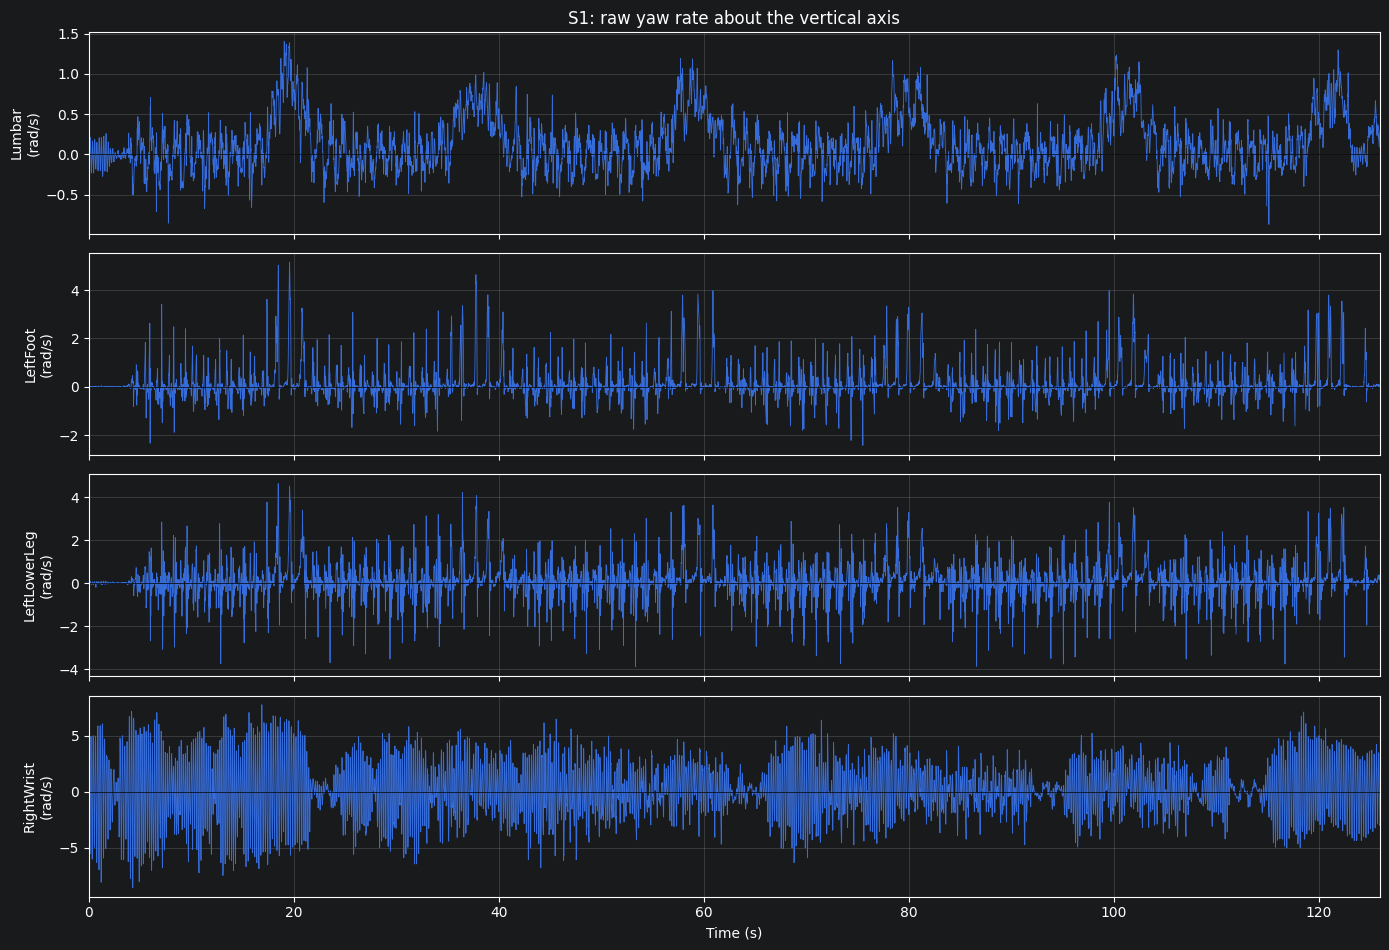

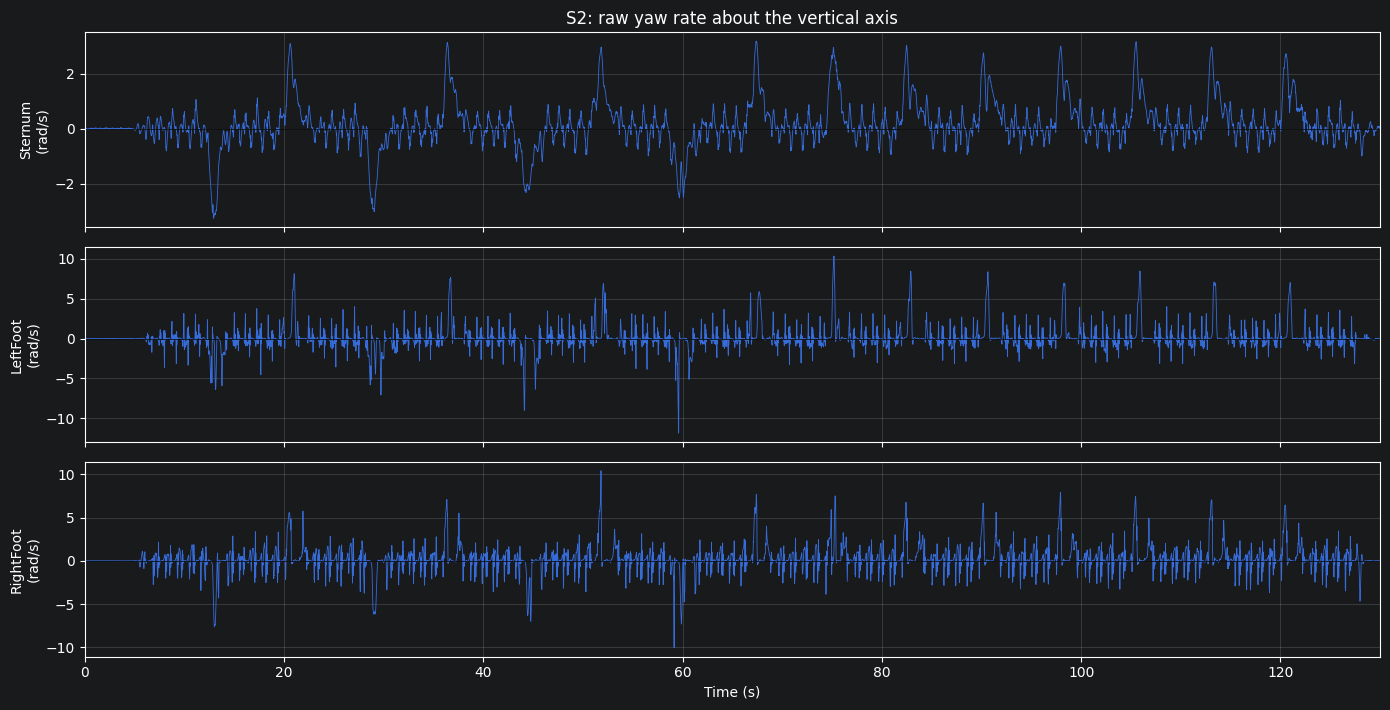

In [3]:
# --- Cell 2: Raw yaw-rate signals, one figure per subject ---
def plot_raw(subj):
    sig = data[subj]
    fig, axes = plt.subplots(len(sig), 1, figsize=(14, 2.4 * len(sig)), sharex=True)
    for ax, (s, x) in zip(axes, sig.items()):
        t = np.arange(len(x)) / fs
        ax.plot(t, x, lw=0.6)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_ylabel(f"{s}\n(rad/s)")
        ax.set_xlim(t[0], t[-1])          # full span, no white space
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{subj}: raw yaw rate about the vertical axis")
    axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    plt.show()

for subj in data:
    plot_raw(subj)

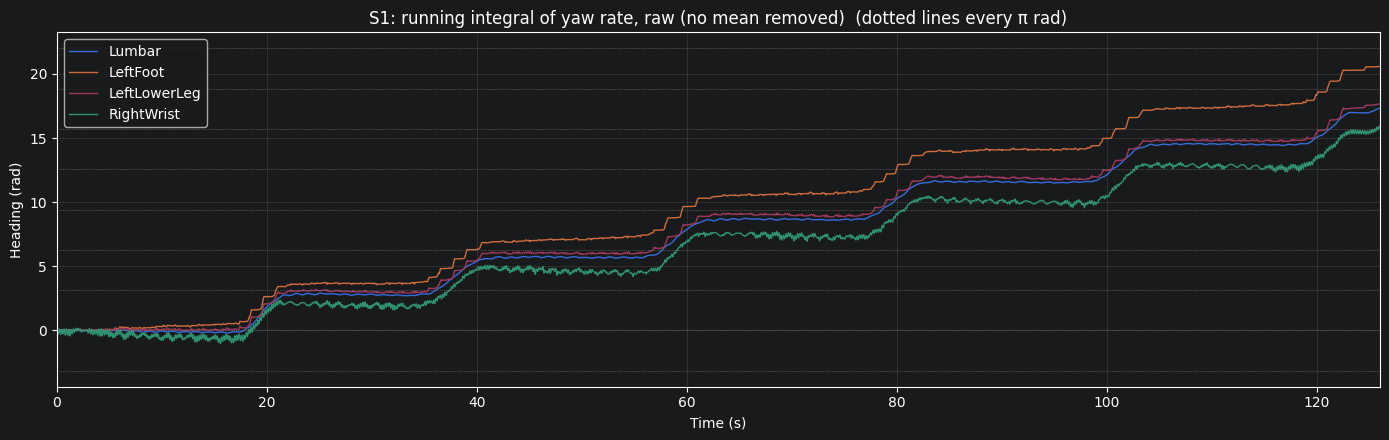

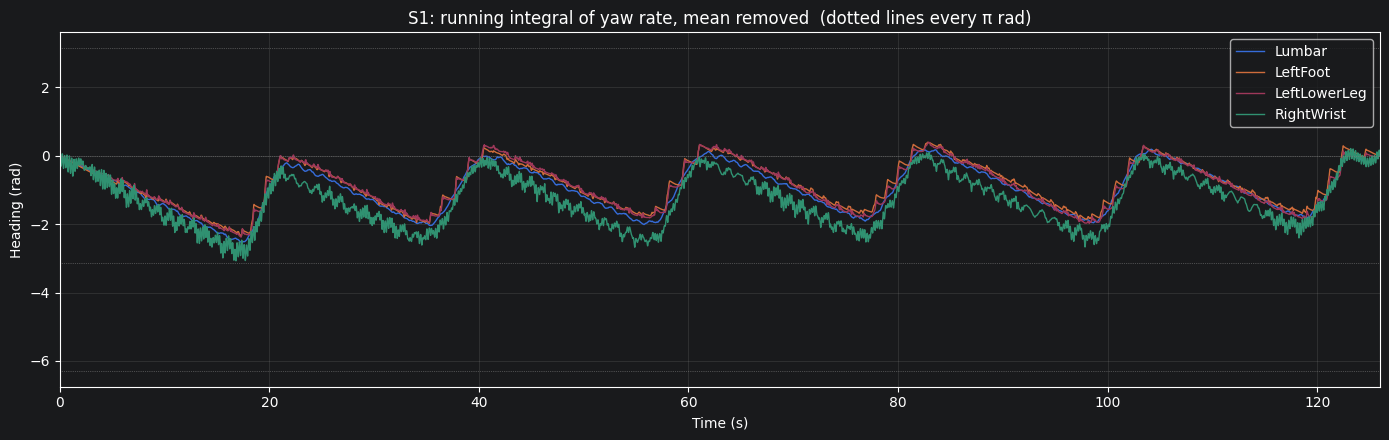

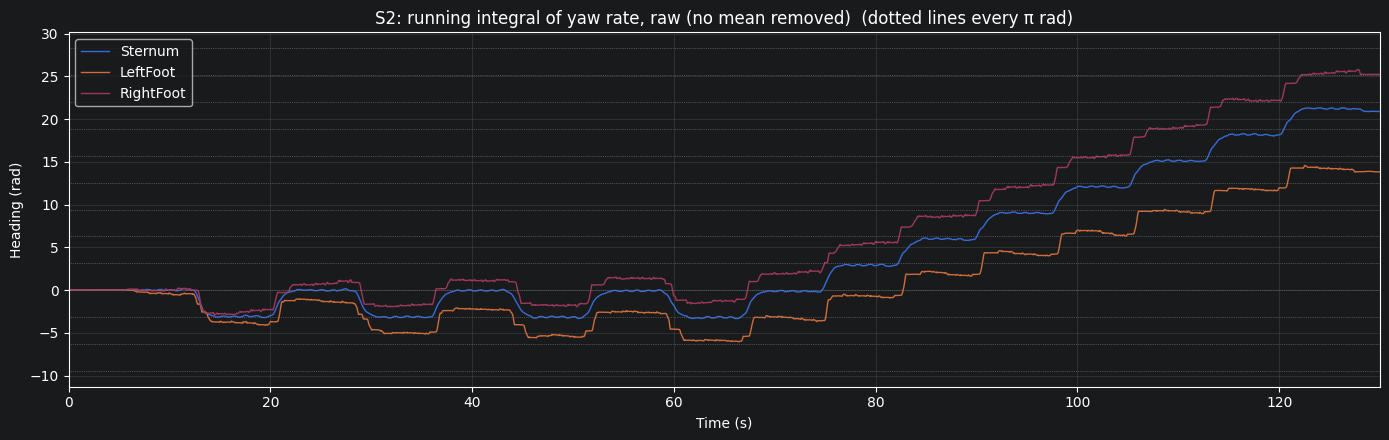

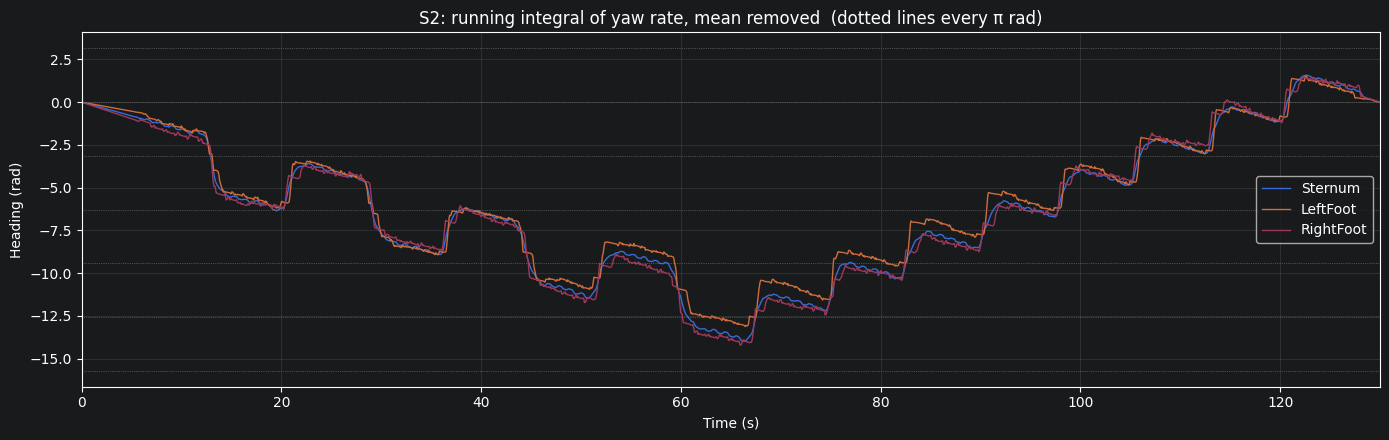

In [4]:
# --- Cell 3: Running integral (heading angle) of each sensor ---
# theta[n] = (1/fs) * sum_{k<=n} omega[k]; a 180-degree turn shows up as a step of about +/- pi rad.
def plot_heading(subj, remove_mean=False):
    sig = data[subj]
    fig, ax = plt.subplots(figsize=(14, 4.5))
    for s, x in sig.items():
        x = x - x.mean() if remove_mean else x
        t = np.arange(len(x)) / fs
        theta = np.cumsum(x) / fs
        ax.plot(t, theta, lw=1.0, label=s)
    # Reference grid lines every pi rad (each 180-degree turn)
    lo, hi = ax.get_ylim()
    for k in range(int(np.floor(lo / np.pi)), int(np.ceil(hi / np.pi)) + 1):
        ax.axhline(k * np.pi, color="gray", lw=0.5, ls=":")
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Heading (rad)")
    title = "mean removed" if remove_mean else "raw (no mean removed)"
    ax.set_title(f"{subj}: running integral of yaw rate, {title}  (dotted lines every \u03c0 rad)")
    ax.legend(loc="best")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

for subj in data:
    plot_heading(subj)                    # as recorded
    plot_heading(subj, remove_mean=True)  # compare: does removing the mean help or hurt?

## Findings from the Raw Signals and Running Integrals

### Subject 1 (Lumbar, Left Foot, Left Lower Leg, Right Wrist; 126 s)
- **Lumbar is the clearest channel:** six broad positive bumps (about 0.7–1.3 rad/s, each lasting about 3–4 s) near **19, 38, 59, 81, 102, and 122 s**. Between turns the signal sits around zero with stride ripple of about ±0.5 rad/s.
- **About 20 s per pass,** which fits 20 m at roughly 1 m/s. S1 turns slowly and gradually.
- **Every turn has the same sign (positive).** Under the right-hand rule with the z-axis pointing up, positive means **CCW** viewed from above.
- **Left foot and lower leg:** sharp spikes once per stride, separated by flat zero stretches while the foot is planted. During turns the spikes get taller and lean positive, from the foot pivoting in steps. Both channels are flat for the first ~4 s while the subject stands still.
- **Right wrist:** a large ±5–8 rad/s oscillation at about **4.6 Hz**. That is too fast for arm swing (stride is about 0.8 Hz), and its amplitude changes don't line up with the turns. **Not useful for detecting turns.**
- **Heading (raw integral):** six steps of about π each. Lumbar ends at **17.3 rad (about 5.5π)**, so each turn averages slightly under 180°. The left foot overshoots (about 20.5 rad), so foot heading does not reliably match body heading.
- **Heading with the mean removed:** turns into a sawtooth. This shows the positive mean comes from **real turning, not sensor bias**, so the mean should not be removed before filtering. The trunk reading of about 0 rad/s while the subject stands still at the start backs this up.
- **Edge case:** the lumbar signal starts rising again at about 124–126 s, which may be a turn cut off at the end of the recording. Partial turns need a stated rule.

### Subject 2 (Sternum, Left Foot, Right Foot; 130 s)
- **Sternum is very clean:** narrow peaks of about ±2–3 rad/s, each lasting about **1–1.5 s**, with **15 turns** about every 7.7 s.
- **The direction pattern changes partway through:**
  - Turns 1–8 **alternate**: negative near 13, 29, 44.5, and 60 s; positive near 21, 37, 52, and 67.6 s.
  - Turns 9–15 are **all positive**: near 75, 83, 90.5, 98, 106, 113, and 121 s.
- **Turn shape:** many peaks rise sharply and then fall more slowly, which suggests a pivot followed by a step to finish the turn.
- **Feet:** each turn shows a large spike (5–10 rad/s) with the same sign as the sternum peak. Flat stretches between strides mark stance.
- **The feet disagree on heading:** left ends near 14 rad, right near 25 rad, sternum at 20.9 rad. **Averaging the two feet comes out close to the sternum** because their errors roughly cancel.
- **Heading total:** sternum ends at 20.9 rad (about 6.7π), consistent with a net of 11 positive − 4 negative = 7 turns.
- **Heading with the mean removed:** distorted here as well, which again says to leave the mean in.
- **Timing doesn't fit the assignment description:** 7.7 s per pass would mean about 2.6 m/s for 20 m, which is running speed. S2 probably walked a shorter course.

### What This Means for the Design
- **Detect turns from the trunk sensors** (lumbar for S1, sternum for S2), use the feet only as supporting evidence, and leave out or heavily down-weight the wrist.
- **The two subjects need different things from the filter:** S1's turns are slow (energy below about 0.3 Hz), while S2's are fast (energy reaching about 0.5–1 Hz, overlapping its stride rate of about 0.9 Hz). A cutoff tuned for S1 would smear S2's turns.
- **Candidate filter:** a moving average about one stride period long (about 1.1–1.25 s). It puts a null at the stride frequency and its harmonics while keeping S2's short turns intact.
- **Validation:** each detected turn should integrate to about ±π rad.

## Problem 2: Design and implement a filter to help detect the turns. Describe and provide the rationale for your filter design.

## PSD of Recordings to Determine Cutoff Frequencies

S1-Lumbar: stride peak = 0.844 Hz
    power below 0.2 Hz:  64.5 %
    power below 0.3 Hz:  65.4 %
    power below 0.4 Hz:  65.9 %
    power below 0.5 Hz:  66.4 %
    power below 0.6 Hz:  67.0 %
S1-LeftFoot: stride peak = 0.812 Hz
    power below 0.2 Hz:  15.7 %
    power below 0.3 Hz:  15.9 %
    power below 0.4 Hz:  16.0 %
    power below 0.5 Hz:  16.3 %
    power below 0.6 Hz:  17.1 %
S1-LeftLowerLeg: stride peak = 0.812 Hz
    power below 0.2 Hz:  11.3 %
    power below 0.3 Hz:  11.5 %
    power below 0.4 Hz:  11.6 %
    power below 0.5 Hz:  11.7 %
    power below 0.6 Hz:  12.1 %
S2-Sternum: stride peak = 0.906 Hz
    power below 0.2 Hz:  54.7 %
    power below 0.3 Hz:  67.4 %
    power below 0.4 Hz:  74.8 %
    power below 0.5 Hz:  79.6 %
    power below 0.6 Hz:  82.1 %
S2-RightFoot: stride peak = 0.781 Hz
    power below 0.2 Hz:  17.0 %
    power below 0.3 Hz:  20.2 %
    power below 0.4 Hz:  22.9 %
    power below 0.5 Hz:  26.3 %
    power below 0.6 Hz:  29.3 %
S2-LeftFoot: strid

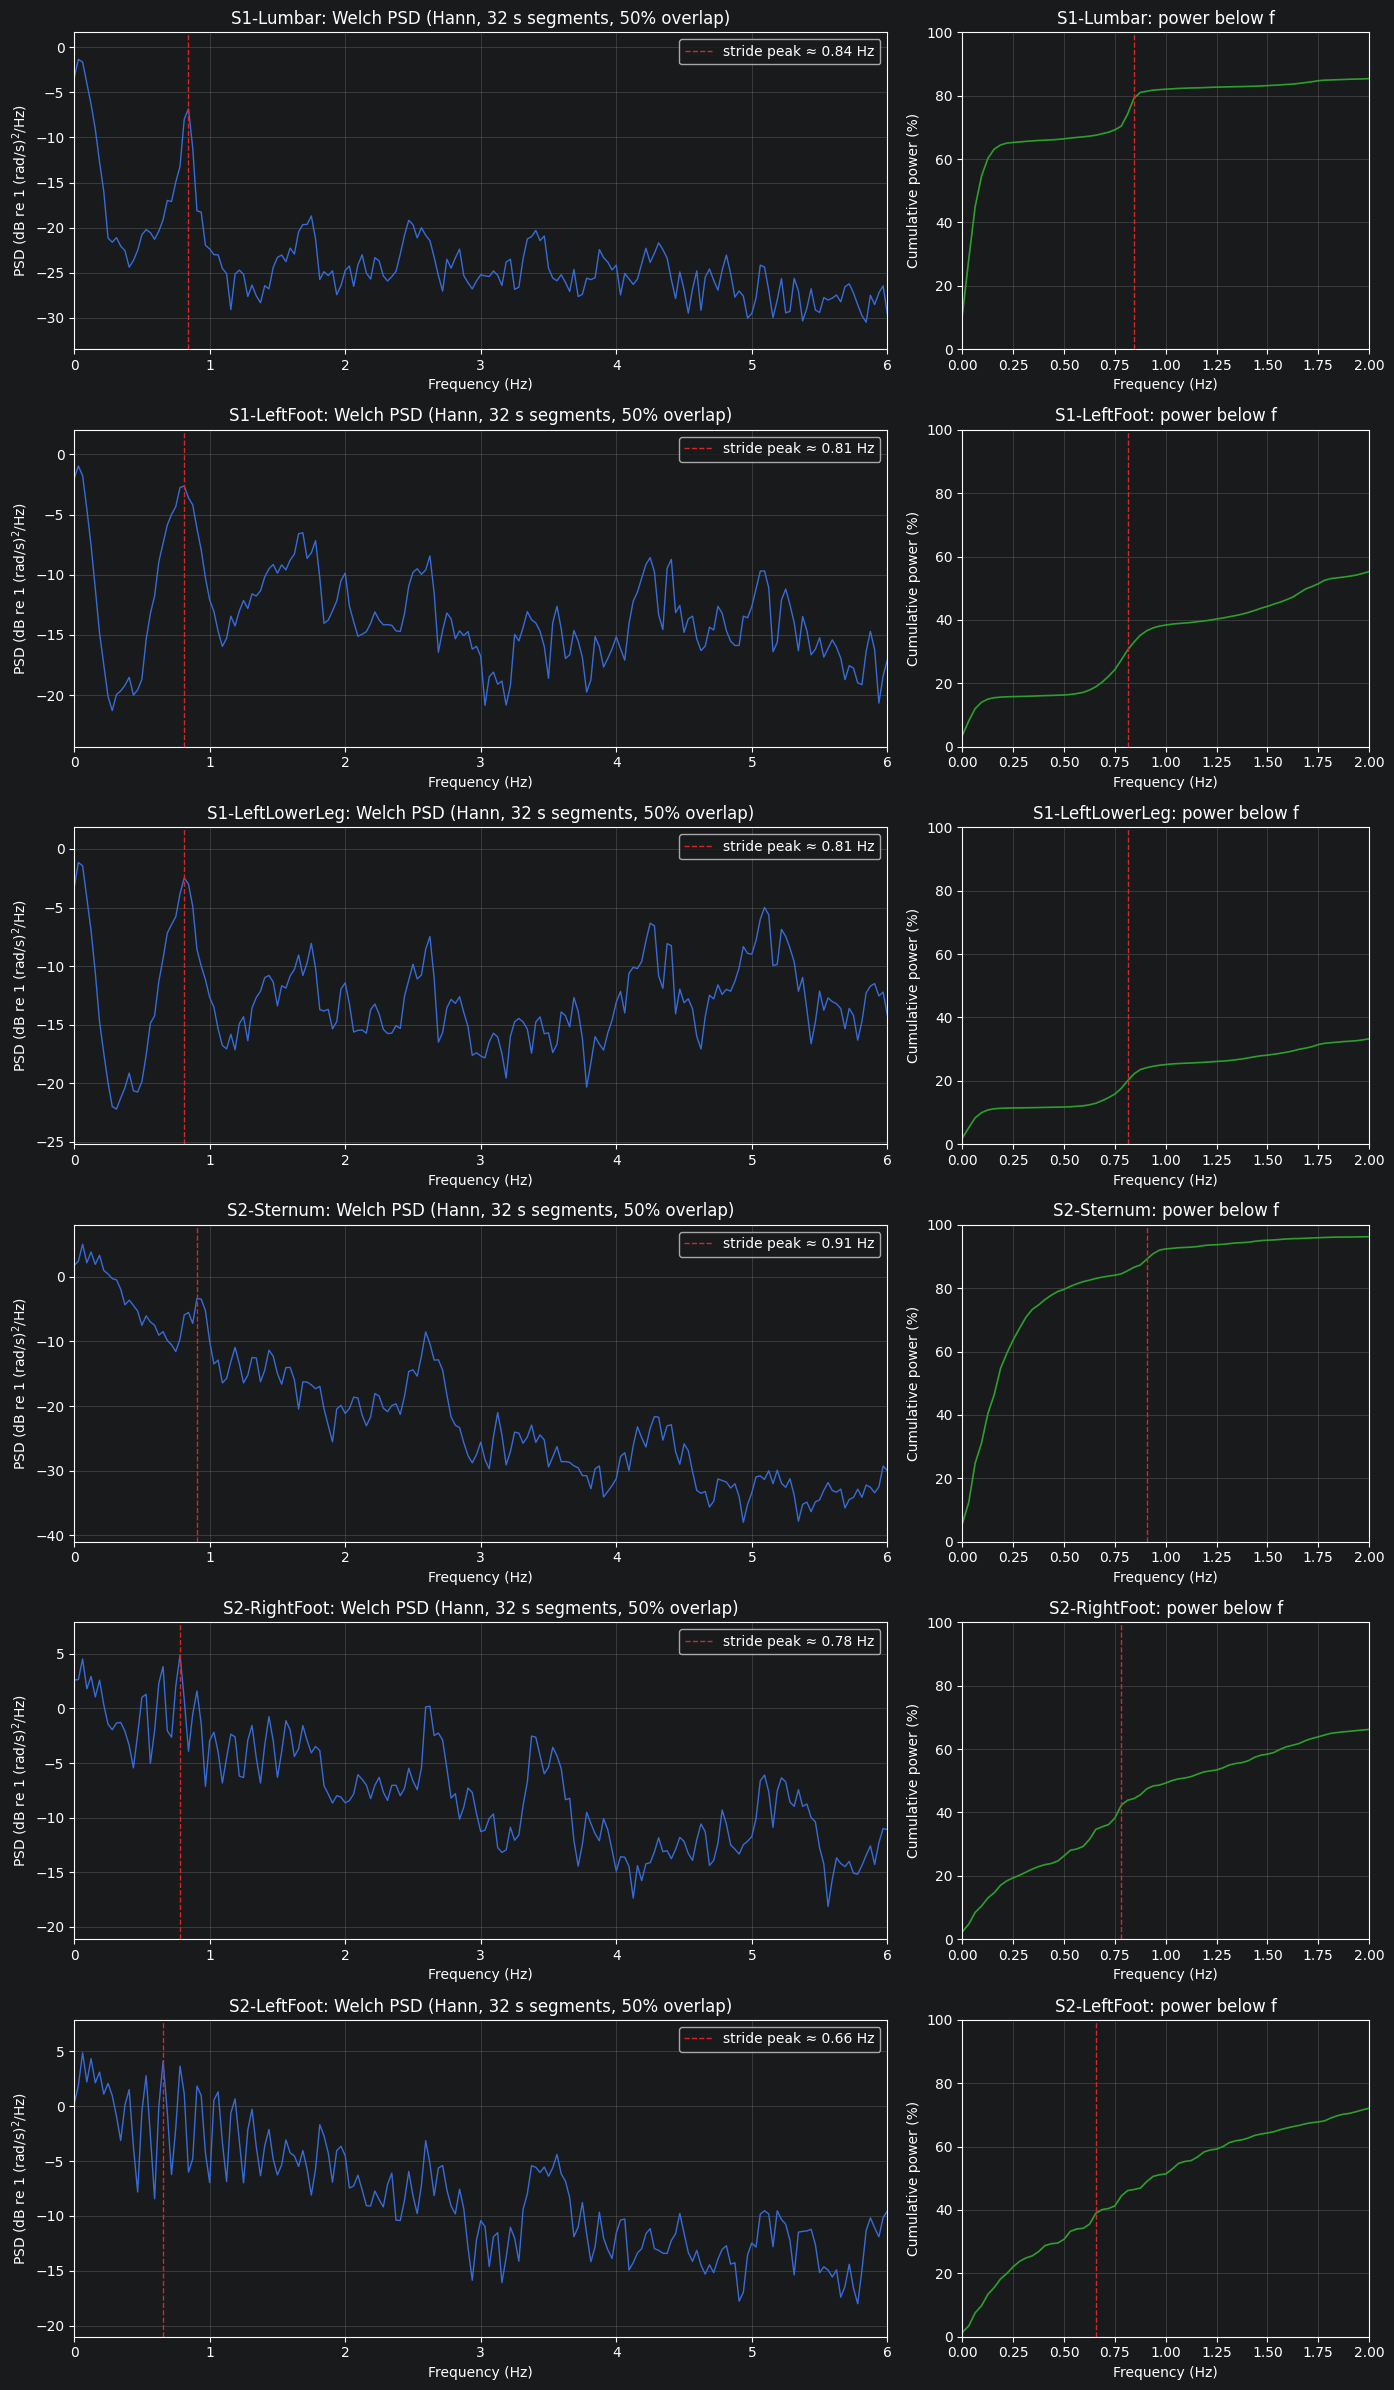

In [11]:
# --- Cell 4: Power spectral density of the sensors (Welch's method) ---
from scipy.signal import welch

psd_channels = [("S1", "Lumbar"), ("S1", "LeftFoot"), ("S1", "LeftLowerLeg"), ("S2", "Sternum"), ("S2", "RightFoot"), ("S2", "LeftFoot")]
nperseg = 4096          # 32 s segments -> 0.03125 Hz resolution (needed to resolve the low-frequency turn content)
f_max_plot = 6.0        # Hz shown on the x-axis

fig, axes = plt.subplots(len(psd_channels), 2, figsize=(14, 4.0 * len(psd_channels)),
                         gridspec_kw={"width_ratios": [2, 1]})

for row, (subj, s) in zip(axes, psd_channels):
    x = data[subj][s]
    f, Pxx = welch(x, fs=fs, window="hann", nperseg=nperseg, noverlap=nperseg // 2, detrend=False)
    PdB = 10 * np.log10(Pxx)

    # Stride peak: largest PSD value between 0.6 and 2 Hz
    band = (f >= 0.6) & (f <= 2.00)
    f_stride = f[band][np.argmax(Pxx[band])]

    # Cumulative fraction of total power below each frequency
    cum = np.cumsum(Pxx) / np.sum(Pxx)

    # Left: PSD in dB
    ax = row[0]
    ax.plot(f, PdB, lw=1.0)
    ax.axvline(f_stride, color="tab:red", ls="--", lw=1, label=f"stride peak \u2248 {f_stride:.2f} Hz")
    ax.set_xlim(0, f_max_plot)
    ax.set_ylim(PdB[f <= f_max_plot].min() - 3, PdB.max() + 3)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (dB re 1 (rad/s)$^2$/Hz)")
    ax.set_title(f"{subj}-{s}: Welch PSD (Hann, {nperseg/fs:.0f} s segments, 50% overlap)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

    # Right: zoom on 0-2 Hz with cumulative power
    ax = row[1]
    zoom = f <= 2.0
    ax.plot(f[zoom], 100 * cum[zoom], lw=1.2, color="tab:green")
    ax.axvline(f_stride, color="tab:red", ls="--", lw=1)
    ax.set_xlim(0, 2.0)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Cumulative power (%)")
    ax.set_title(f"{subj}-{s}: power below f")
    ax.grid(alpha=0.3)

    # Print a few reference numbers for choosing the cutoff
    print(f"{subj}-{s}: stride peak = {f_stride:.3f} Hz")
    for fc in (0.2, 0.3, 0.4, 0.5, 0.6):
        print(f"    power below {fc:.1f} Hz: {100 * cum[f <= fc][-1]:5.1f} %")

fig.tight_layout()
plt.show()

**Final Filter Design**
| Subject | Filter Type | Cutoff | Order |
|---|---|---|---|
| S1 | Lowpass Butterworth, sosfiltfilt | 0.40 Hz | 3 |
| S2 | Lowpass Butterworth, sosfiltfilt | 0.5 Hz | 4 |

In [12]:
# --- Cell 5: Filter design (one lowpass Butterworth per subject, SOS form, zero-phase via sosfiltfilt) ---
from scipy.signal import butter, sosfilt, sosfiltfilt, sosfreqz

filter_spec = {
    #       cutoff (Hz)  order  stride peak (Hz, from the trunk-sensor PSD)
    "S1": {"fc": 0.40, "N": 3, "f_stride": 0.84},
    "S2": {"fc": 0.50, "N": 4, "f_stride": 0.91},
}

sos = {}
for subj, p in filter_spec.items():
    sos[subj] = butter(p["N"], p["fc"], btype="low", fs=fs, output="sos")

    # Theoretical Butterworth attenuation at the stride peak
    r = p["f_stride"] / p["fc"]
    A1 = 10 * np.log10(1 + r ** (2 * p["N"]))   # single pass (dB)
    print(f"{subj}: fc = {p['fc']:.2f} Hz, N = {p['N']} "
          f"-> attenuation at stride ({p['f_stride']:.2f} Hz): "
          f"{A1:5.1f} dB single pass, {2 * A1:5.1f} dB with sosfiltfilt "
          f"(effective order {2 * p['N']})")

S1: fc = 0.40 Hz, N = 3 -> attenuation at stride (0.84 Hz):  19.4 dB single pass,  38.8 dB with sosfiltfilt (effective order 6)
S2: fc = 0.50 Hz, N = 4 -> attenuation at stride (0.91 Hz):  20.8 dB single pass,  41.7 dB with sosfiltfilt (effective order 8)


## Filter Responses

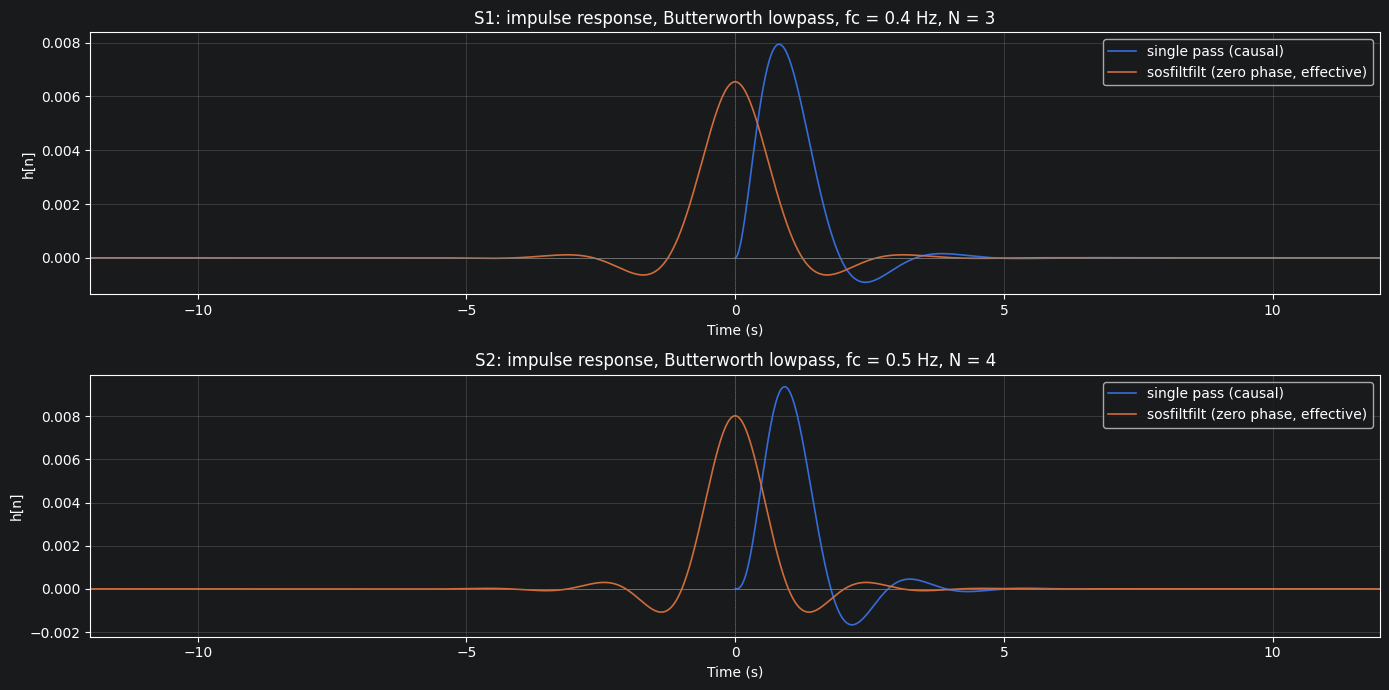

In [13]:
# --- Cell 6: Impulse response (single pass vs. effective zero-phase sosfiltfilt) ---
T_imp = 12.0                                  # seconds shown on each side
n_half = int(T_imp * fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, subj in zip(axes, filter_spec):
    p = filter_spec[subj]

    # Single pass (causal): impulse at n = 0
    d = np.zeros(n_half + 1); d[0] = 1.0
    h1 = sosfilt(sos[subj], d)
    t1 = np.arange(len(h1)) / fs

    # Effective sosfiltfilt response (non-causal, symmetric): impulse in the middle of a long buffer
    d2 = np.zeros(2 * n_half + 1); d2[n_half] = 1.0
    h2 = sosfiltfilt(sos[subj], d2)
    t2 = (np.arange(len(h2)) - n_half) / fs

    ax.plot(t1, h1, lw=1.2, label="single pass (causal)")
    ax.plot(t2, h2, lw=1.2, label="sosfiltfilt (zero phase, effective)")
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5, ls=":")
    ax.set_xlim(-T_imp, T_imp)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("h[n]")
    ax.set_title(f"{subj}: impulse response, Butterworth lowpass, fc = {p['fc']} Hz, N = {p['N']}")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

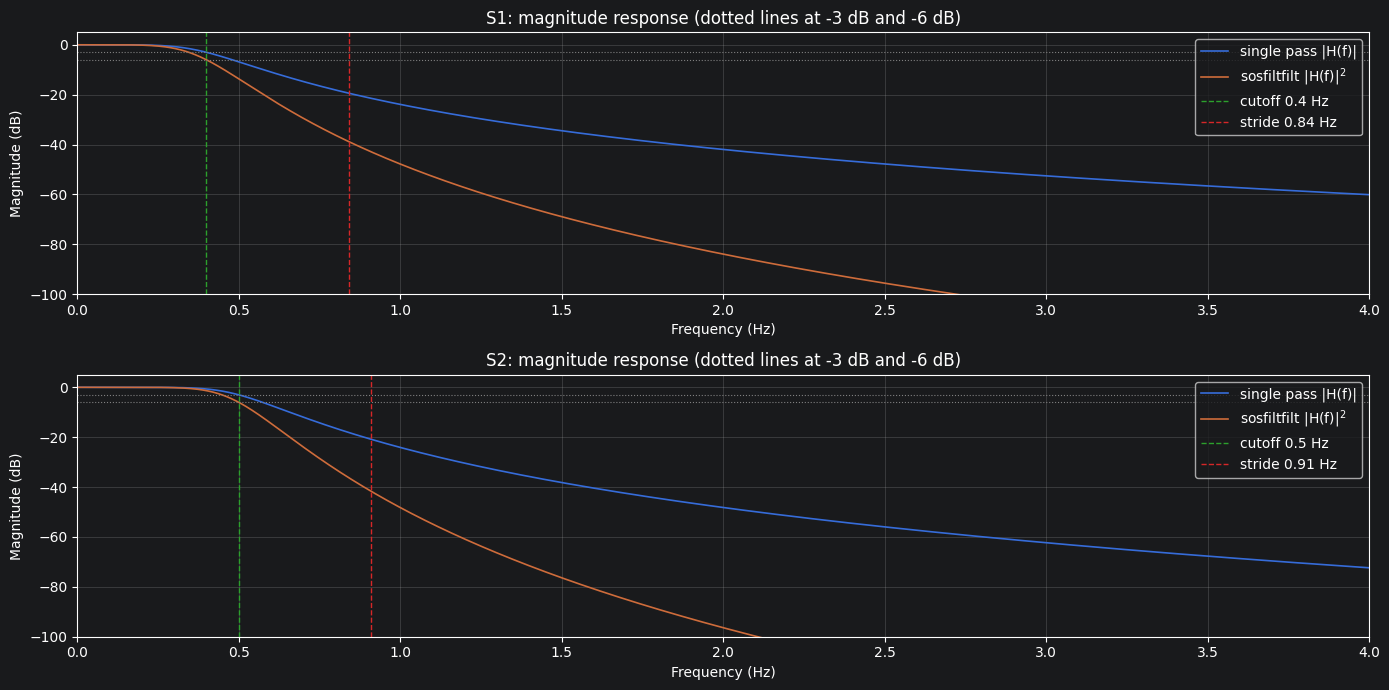

In [14]:
# --- Cell 7: Magnitude response ---
f_resp = np.linspace(0, 4.0, 4000)            # Hz; zoomed to the band that matters
f_resp[0] = 1e-6                              # avoid exactly 0 Hz

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, subj in zip(axes, filter_spec):
    p = filter_spec[subj]
    _, H = sosfreqz(sos[subj], worN=f_resp, fs=fs)
    mag1 = 20 * np.log10(np.abs(H) + 1e-300)  # single pass
    mag2 = 2 * mag1                           # sosfiltfilt: |H|^2

    ax.plot(f_resp, mag1, lw=1.2, label="single pass |H(f)|")
    ax.plot(f_resp, mag2, lw=1.2, label="sosfiltfilt |H(f)|$^2$")
    ax.axvline(p["fc"], color="tab:green", ls="--", lw=1, label=f"cutoff {p['fc']} Hz")
    ax.axvline(p["f_stride"], color="tab:red", ls="--", lw=1, label=f"stride {p['f_stride']} Hz")
    ax.axhline(-3, color="gray", ls=":", lw=0.8)
    ax.axhline(-6, color="gray", ls=":", lw=0.8)
    ax.set_xlim(0, f_resp[-1])
    ax.set_ylim(-100, 5)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Magnitude (dB)")
    ax.set_title(f"{subj}: magnitude response (dotted lines at -3 dB and -6 dB)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

S1: single-pass group delay near DC = 0.80 s (sosfiltfilt removes this delay)
S2: single-pass group delay near DC = 0.83 s (sosfiltfilt removes this delay)


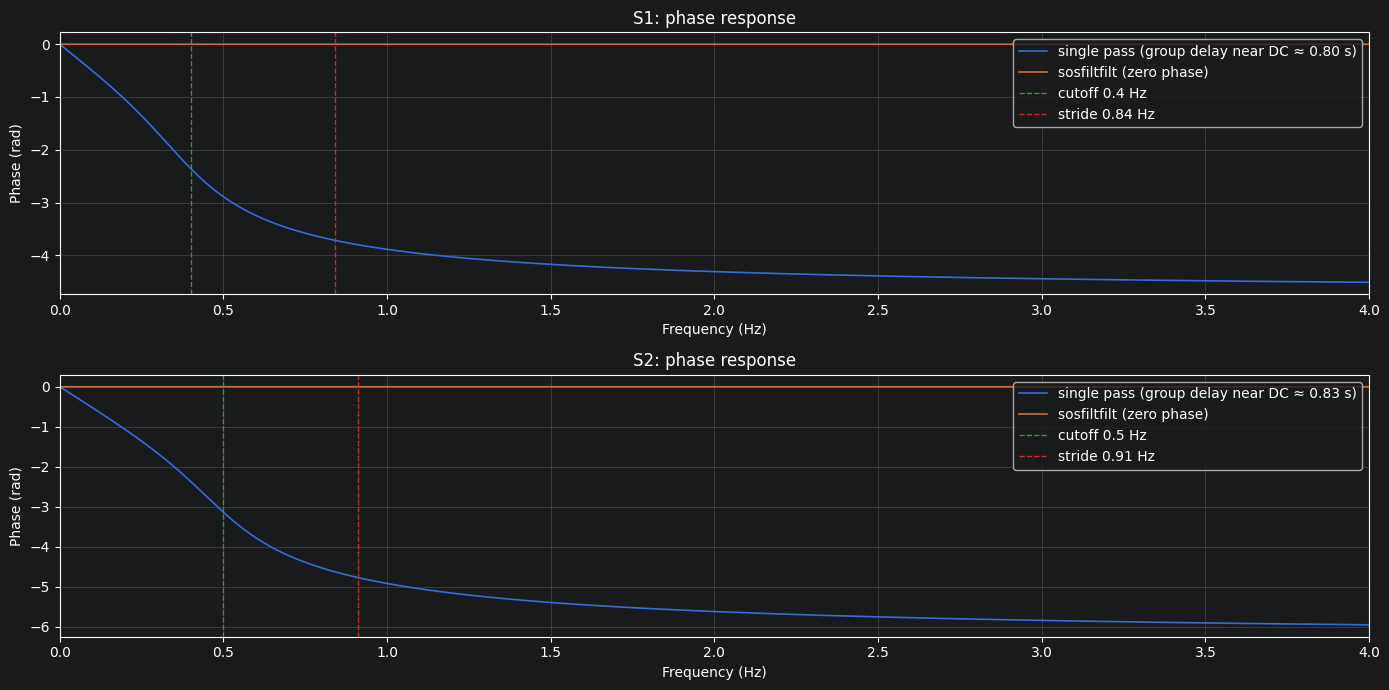

In [15]:
# --- Cell 8: Phase response ---
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, subj in zip(axes, filter_spec):
    p = filter_spec[subj]
    _, H = sosfreqz(sos[subj], worN=f_resp, fs=fs)
    phase1 = np.unwrap(np.angle(H))           # single pass (rad)

    # Group delay near DC = -d(phase)/d(omega), omega = 2*pi*f
    gd = -np.gradient(phase1, 2 * np.pi * f_resp)
    gd_dc = gd[f_resp < 0.05].mean()

    ax.plot(f_resp, phase1, lw=1.2, label=f"single pass (group delay near DC \u2248 {gd_dc:.2f} s)")
    ax.plot(f_resp, np.zeros_like(f_resp), lw=1.2, label="sosfiltfilt (zero phase)")
    ax.axvline(p["fc"], color="tab:green", ls="--", lw=1, label=f"cutoff {p['fc']} Hz")
    ax.axvline(p["f_stride"], color="tab:red", ls="--", lw=1, label=f"stride {p['f_stride']} Hz")
    ax.set_xlim(0, f_resp[-1])
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Phase (rad)")
    ax.set_title(f"{subj}: phase response")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    print(f"{subj}: single-pass group delay near DC = {gd_dc:.2f} s "
          f"(sosfiltfilt removes this delay)")
fig.tight_layout()
plt.show()

## Filtered Time Signals

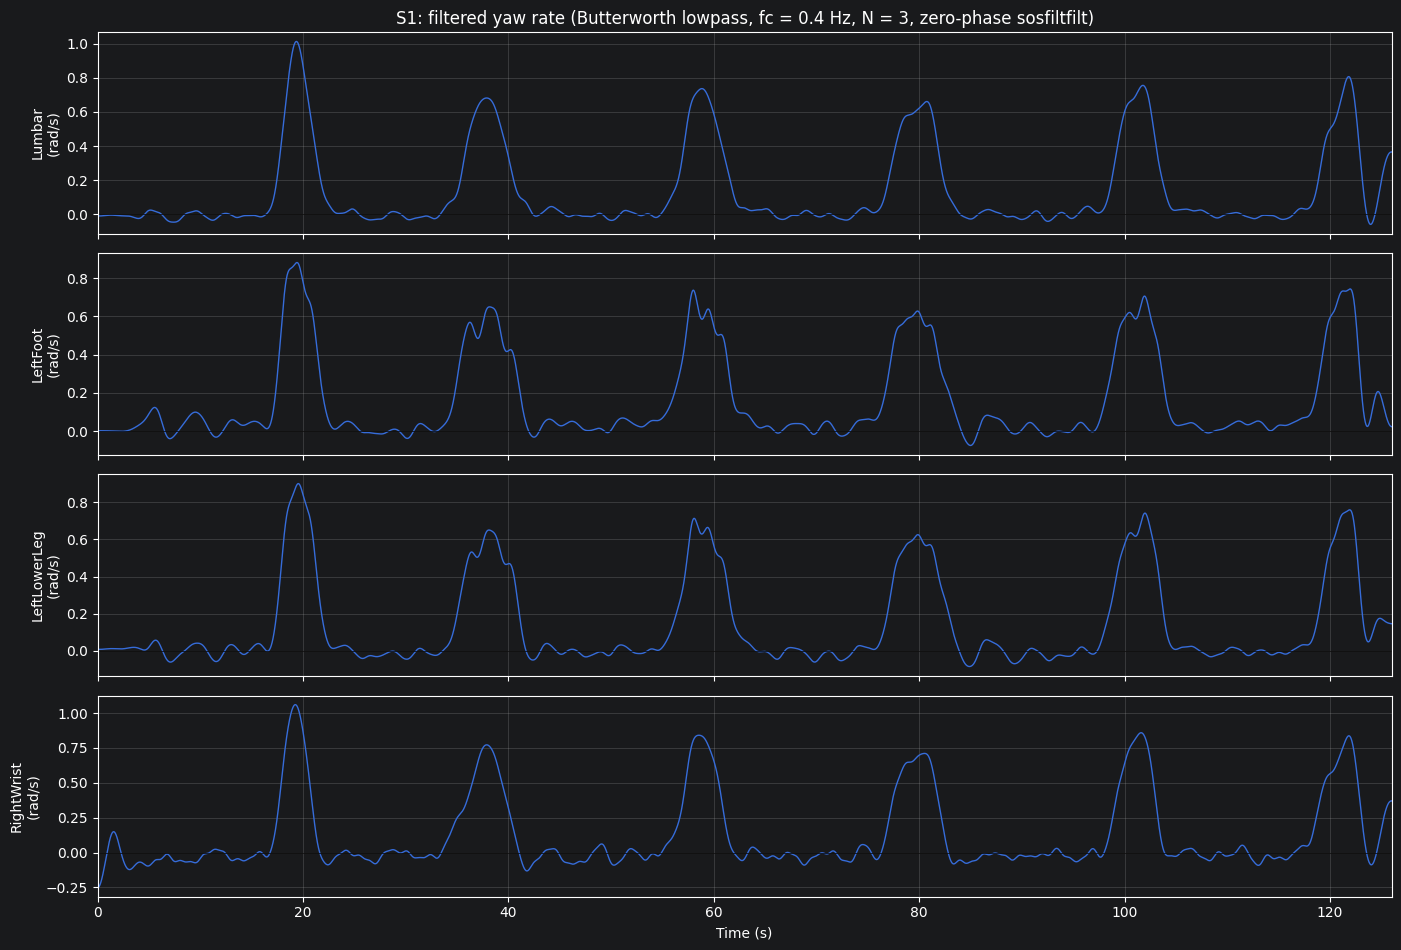

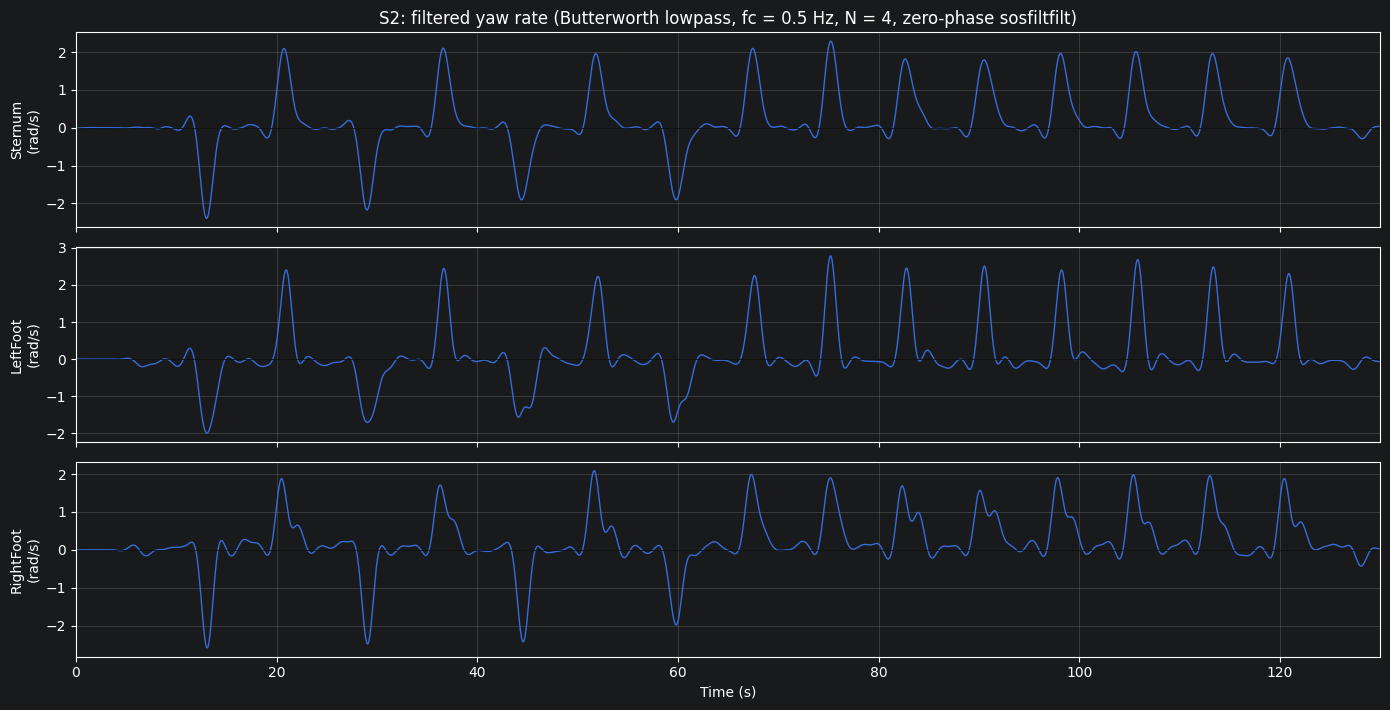

In [16]:
# --- Cell 9: Apply each subject's filter to all of that subject's sensors and plot ---
# Edge handling: mirror ("even") padding of 4 s at each end. The default odd padding reflects about the
# first/last sample, which creates a large start-up transient when a channel starts mid-swing (e.g. the wrist).
PADLEN = int(4 * fs)

def apply_filter(subj, x):
    return sosfiltfilt(sos[subj], x, padtype="even", padlen=PADLEN)

filt = {subj: {s: apply_filter(subj, x) for s, x in sig.items()} for subj, sig in data.items()}

def plot_filtered(subj):
    sig = filt[subj]
    p = filter_spec[subj]
    fig, axes = plt.subplots(len(sig), 1, figsize=(14, 2.4 * len(sig)), sharex=True)
    for ax, (s, y) in zip(axes, sig.items()):
        t = np.arange(len(y)) / fs
        ax.plot(t, y, lw=1.0)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_ylabel(f"{s}\n(rad/s)")
        ax.set_xlim(t[0], t[-1])
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{subj}: filtered yaw rate (Butterworth lowpass, fc = {p['fc']} Hz, "
                      f"N = {p['N']}, zero-phase sosfiltfilt)")
    axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    plt.show()

for subj in filt:
    plot_filtered(subj)

## Problem 2 Rationale

### Design
| Subject | Filter | Cutoff $f_c$ | Order $N$ | Applied with | Applied to |
|---|---|---|---|---|---|
| S1 | Lowpass Butterworth (IIR, SOS form) | 0.40 Hz | 3 | `sosfiltfilt` (zero phase, even padding) | all 4 sensors |
| S2 | Lowpass Butterworth (IIR, SOS form) | 0.50 Hz | 4 | `sosfiltfilt` (zero phase, even padding) | all 3 sensors |

### Why a lowpass filter
The signal contains turn rotation plus stride rotation, arm swing, and noise. The PSDs of the trunk sensors show these in different frequency bands:
- **Turns** are slow, single bumps lasting a few seconds, so their energy sits at low frequencies. About 65% of the S1 lumbar power is below 0.2 Hz, and about 80% of the S2 sternum power is below 0.5 Hz.
- **Stride** produces a clear peak at **0.84 Hz (S1)** and **0.91 Hz (S2)**. Arm swing and the other motion sit at higher frequencies.

A lowpass filter with its cutoff between the turn band and the stride peak keeps the turns and removes the rest. A **bandpass** filter is not needed: the running integrals showed that the nonzero mean is real turning, not sensor bias, so DC must be kept. A lowpass filter has unity gain at 0 Hz.

### Why Butterworth
The transition band is very narrow, about 0.4 Hz wide at a 128 Hz sample rate. Its passband is also maximally flat, with no ripple, so the turn amplitude (and therefore the threshold level) is not distorted.

### Why these cutoffs
- **S1 (0.40 Hz):** the cumulative-power curve is flat between 0.2 and 0.6 Hz (64.5% to 67.0%), so there is no turn energy to lose in that range. A cutoff at 0.40 Hz sits in the middle of the valley, a factor of 2.1 below the stride peak.
- **S2 (0.50 Hz):** S2's turns last only about 1 s, so their energy reaches higher: 75% of the power is below 0.4 Hz and 80% below 0.5 Hz. A cutoff of 0.5 Hz keeps most of that energy while staying a factor of 1.8 below the stride peak.
- **One cutoff per subject, applied to all of that subject's sensors.** The stride rate belongs to the subject, not the sensor. Using the same filter on every sensor of a subject also keeps the turn timing consistent across channels. The cutoffs were chosen from the trunk-sensor PSDs, which are the clearest.

### Why these orders
With `sosfiltfilt`, the filter runs forward and backward, which squares the magnitude response (doubling the attenuation in dB) and doubles the effective order. The attenuation at the stride frequency is $A(f) = 10\log_{10}\!\big(1+(f/f_c)^{2N}\big)$ dB for one pass.

| Subject | $f_{stride}/f_c$ | One pass | With `sosfiltfilt` |
|---|---|---|---|
| S1 ($N=3$) | 2.1 | 19.4 dB | **38.8 dB** |
| S2 ($N=4$) | 1.8 | 20.8 dB | **41.7 dB** |

S2's cutoff is closer to its stride peak, so it gets one more order. Both designs reach about 40 dB of stride rejection. I did not use a higher order because it brings more ringing around each turn, which could cause false threshold crossings during detection.

### Why `sosfiltfilt` (zero phase, SOS form)
- **Zero phase:** the phase plot shows that a single forward pass delays the signal by about **0.80 s (S1)** and **0.83 s (S2)**. That would shift every detected start and end late by the same amount. Filtering forward and backward cancels the delay, so the turn edges stay at their true times. The cost is that the filter is non-causal, which is fine for offline analysis.
- **SOS form:** the cutoffs are below 1% of the Nyquist frequency (64 Hz). At that ratio the poles are very close to $z=1$, and a filter written as one high-order $(b, a)$ polynomial (`filtfilt`) can lose accuracy or become unstable from rounding error. A cascade of second-order sections avoids this.
- **Mirror (even) edge padding:** the default odd padding created a false 7 rad/s spike at the start of the S1 wrist signal, because that recording begins in the middle of an arm swing. Mirror padding of 4 s at each end removes the spike.

### Limitation
A lowpass filter spreads every turn a little in time, so turn durations measured on the filtered signal are slightly longer than the real turns. The effect is largest for S1, which has the lower cutoff. Because the same filter is applied to every turn, durations can still be compared with each other.

## Threshold Histograms Using Otsu's Thresholding Method

## Otsu's Thresholding Method

Otsu's method [1] is not covered in the course or the textbook. I used it to choose the turn-detection threshold from the data instead of picking it by eye.

### What it does
Otsu's method picks a threshold $k$ that splits a set of values into two classes, **below** $k$ (class 0) and **above** $k$ (class 1), so that the two classes are as well separated as possible. It uses only the histogram of the data, and it has no tuning parameters. It was originally designed for separating foreground from background in gray-scale images.

### Setup
Divide the data into $L$ histogram bins with centers $x_i$ and probabilities $p_i$ (the fraction of samples in bin $i$), so $\sum_i p_i = 1$. For a candidate threshold $k$, define:

$$w_0(k)=\sum_{i\le k}p_i,\qquad w_1(k)=\sum_{i>k}p_i=1-w_0(k)$$

$$\mu_0(k)=\frac{1}{w_0}\sum_{i\le k}x_i p_i,\qquad \mu_1(k)=\frac{1}{w_1}\sum_{i>k}x_i p_i,\qquad \mu_T=\sum_i x_i p_i = w_0\mu_0+w_1\mu_1$$

Here $w$ is the fraction of samples in each class, $\mu$ is each class's mean, and $\mu_T$ is the overall mean.

### Derivation
The total variance $\sigma_T^2=\sum_i (x_i-\mu_T)^2 p_i$ does not depend on $k$. For each class $c$, write $x-\mu_T=(x-\mu_c)+(\mu_c-\mu_T)$ and expand the square. The cross term $2(\mu_c-\mu_T)\sum(x-\mu_c)p$ vanishes, because deviations from a class's own mean sum to zero. That leaves:

$$\sigma_T^2=\underbrace{w_0\sigma_0^2+w_1\sigma_1^2}_{\sigma_W^2\ \text{(within-class)}}+\underbrace{w_0(\mu_0-\mu_T)^2+w_1(\mu_1-\mu_T)^2}_{\sigma_B^2\ \text{(between-class)}}$$

Since $\mu_T=w_0\mu_0+w_1\mu_1$ and $w_0+w_1=1$, we have $\mu_0-\mu_T=w_1(\mu_0-\mu_1)$ and $\mu_1-\mu_T=-w_0(\mu_0-\mu_1)$. Substituting:

$$\sigma_B^2(k)=w_0w_1^2(\mu_0-\mu_1)^2+w_1w_0^2(\mu_0-\mu_1)^2=\boxed{\,w_0(k)\,w_1(k)\,\big[\mu_0(k)-\mu_1(k)\big]^2\,}$$

Because $\sigma_T^2$ is fixed, **maximizing the between-class variance $\sigma_B^2$ is the same as minimizing the within-class variance $\sigma_W^2$**. The Otsu threshold is therefore

$$k^*=\arg\max_k\ \sigma_B^2(k)$$

It is cheap to compute: $w_0(k)$ and $\sigma_B^2(k)$ come from running cumulative sums of $p_i$ and $x_i p_i$, so one pass over the histogram evaluates every candidate threshold. The red curve in my histogram plots is $\sigma_B^2(k)$ plotted against $k$, and the detected threshold is the location of its peak.

**Intuition:** if $k$ is too low, class 1 swallows most of the walking samples, and its mean moves toward class 0's mean. If $k$ is too high, class 1 has few samples ($w_1\to0$). Either way $\sigma_B^2$ shrinks, so the best split lies in between.

### How it applies to this assignment
- **Which data:** the histogram of $|y[n]|$, the absolute value of the *filtered* trunk signal (lumbar for S1, sternum for S2). Taking the absolute value pools both turn directions into one "turning" class.
- **The two classes:** class 0 is straight walking or standing, a tall, narrow spike near 0 rad/s. Class 1 is turning, a small, spread-out cluster at larger values. Turning takes up about 20% of the samples in each recording.
- **Results:** high threshold $\approx 0.31$ rad/s for S1 and $\approx 0.84$ rad/s for S2. Each is the peak of its $\sigma_B^2$ curve.
- **Role in turn detection:** the high threshold *confirms* that a turn happened, since the filtered signal must exceed it. The *start and end* of the turn are found by moving outward from that point until the signal falls below a lower threshold of $3\hat\sigma$, where $\hat\sigma = 1.4826\cdot\text{MAD}$ is a robust estimate of the walking noise based on the median absolute deviation (MAD) [2], [3]. The note below explains the factor 1.4826. Using two thresholds (hysteresis) keeps noise from creating false turns and also keeps one turn from being split in two.
- **Why this approach:** the thresholds follow from the data instead of from by-eye guesses, so the same procedure works on both subjects even though their turns differ in size. The $\sigma_B^2$ curve has a broad flat top for both subjects, so the detection is not sensitive to the exact threshold value.

### Note: the MAD and the factor 1.4826
The median absolute deviation is $\text{MAD} = \text{median}\big(|y - \text{median}(y)|\big)$. For Gaussian samples $Y \sim \mathcal{N}(\mu,\sigma^2)$, the MAD is the value $m$ with $P(|Y-\mu|\le m)=\tfrac12$. Standardizing with $Z=(Y-\mu)/\sigma$ gives

$$2\,\Phi\!\left(\tfrac{m}{\sigma}\right)-1=\tfrac12 \;\Longrightarrow\; \frac{m}{\sigma}=\Phi^{-1}(0.75)=0.6745 \;\Longrightarrow\; \hat\sigma=\frac{\text{MAD}}{0.6745}=1.4826\cdot\text{MAD}$$

where $\Phi$ is the standard normal CDF. With this scaling, the MAD is a consistent estimator of $\sigma$ for Gaussian noise, so $3\hat\sigma$ keeps its usual meaning: about 99.7% of the walking noise falls within it [2], [3].

**Why not the standard deviation?** The standard deviation squares every deviation, so the turn samples (about 20% of the data) inflate it. The median ignores them as long as fewer than half the samples are turns [3]. On the filtered trunk signals:

| | $1.4826\cdot$MAD | Std. dev. | $3\hat\sigma$ (MAD) | $3\sigma$ (std. dev.) |
|---|---|---|---|---|
| S1-Lumbar | 0.045 rad/s | 0.247 rad/s | **0.13 rad/s** | 0.74 rad/s |
| S2-Sternum | 0.108 rad/s | 0.723 rad/s | **0.32 rad/s** | 2.17 rad/s |

A threshold based on the standard deviation would sit above most of S1's turn peaks (about 0.6–0.8 rad/s) and almost all of S2's (about 2 rad/s), so it would fail. The MAD-based estimate reflects only the walking noise.

### Limitations
- Otsu assumes the histogram has two groups. It works here because the walking spike and the turn cluster are clearly different.
- Heavily unequal classes can bias the threshold toward the larger class. With about 20% turning samples this is a mild effect, and the high threshold only has to separate "clearly turning" from "walking."
- Otsu does not know about time. It labels samples, not turns, so the minimum-duration and minimum-gap rules still have to be applied afterward.
- Otsu sets a threshold on the *filtered* signal, so it does not replace the filter design. The filter order and cutoff were chosen from the PSD and the magnitude response, not from the histogram.

### References
[1] N. Otsu, "A threshold selection method from gray-level histograms," *IEEE Transactions on Systems, Man, and Cybernetics*, vol. 9, no. 1, pp. 62–66, 1979.

[2] P. J. Rousseeuw and C. Croux, "Alternatives to the median absolute deviation," *Journal of the American Statistical Association*, vol. 88, no. 424, pp. 1273–1283, 1993.

[3] P. J. Huber and E. M. Ronchetti, *Robust Statistics*, 2nd ed. Hoboken, NJ: Wiley, 2009.

S1-Lumbar: walking noise sigma = 0.045 rad/s, low threshold = 0.13 rad/s, high threshold (Otsu) = 0.31 rad/s, max inter-class variance = 0.0498 (rad/s)^2, fraction of samples above high = 20.3 %
S2-Sternum: walking noise sigma = 0.108 rad/s, low threshold = 0.32 rad/s, high threshold (Otsu) = 0.84 rad/s, max inter-class variance = 0.3282 (rad/s)^2, fraction of samples above high = 19.7 %


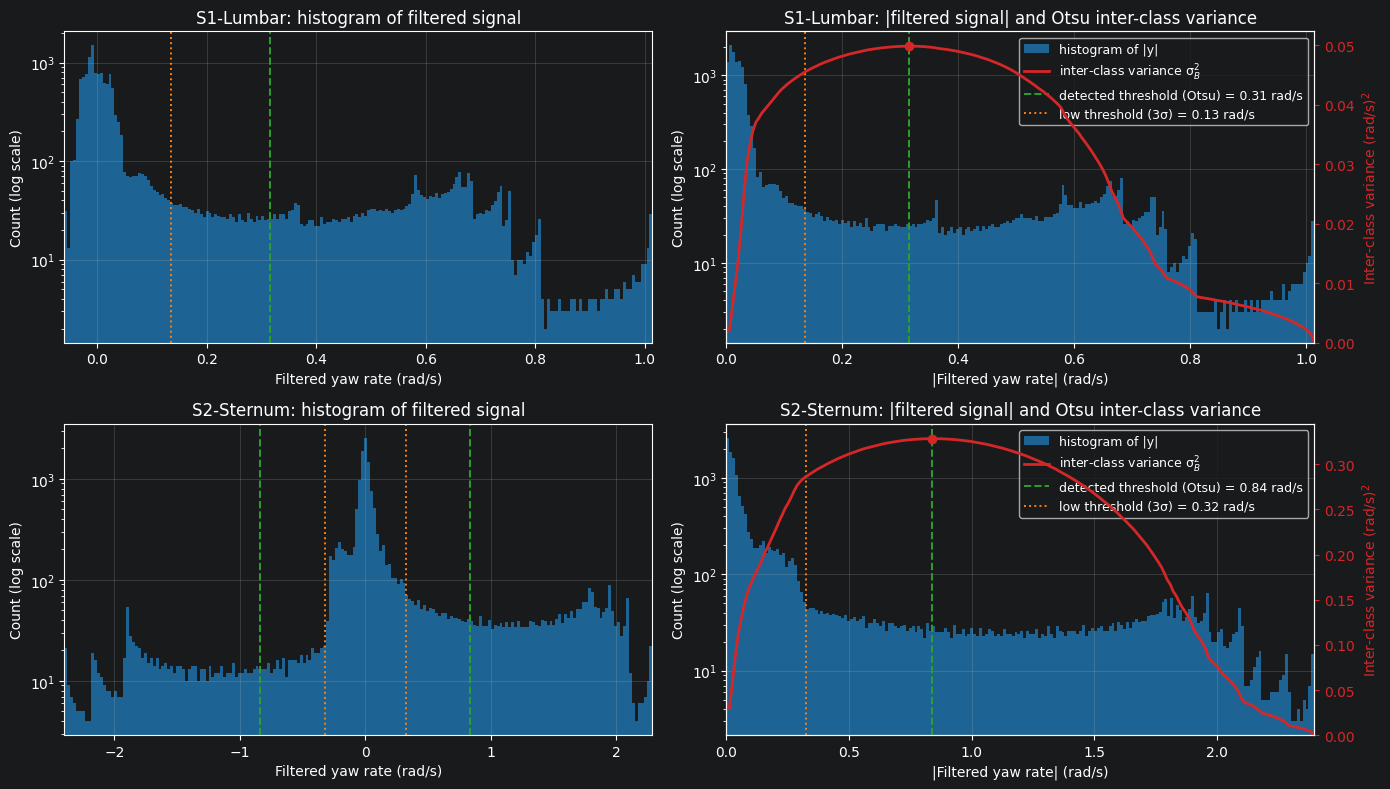

In [24]:
# --- Cell 10: Threshold histograms of the filtered trunk (detection) signals, with Otsu inter-class variance ---
# Detection channel per subject: the trunk sensor (tracks whole-body rotation best).
detect_ch = {"S1": "Lumbar", "S2": "Sternum"}

def otsu_threshold(v, nbins=200):
    """Otsu's method on the histogram of v.
    For every candidate threshold k, split the samples into class 0 (below k) and class 1 (above k) and
    compute the inter-class (between-class) variance  sigma_B^2(k) = w0 * w1 * (mu0 - mu1)^2,
    where w0, w1 are the class probabilities and mu0, mu1 are the class means.
    The threshold is the k that maximizes sigma_B^2.
    Returns (threshold, candidate thresholds, sigma_B^2 curve)."""
    counts, edges = np.histogram(v, bins=nbins)
    p = counts / counts.sum()                 # probability of each bin
    centers = 0.5 * (edges[:-1] + edges[1:])
    w0 = np.cumsum(p)                         # P(class 0)
    w1 = 1.0 - w0                             # P(class 1)
    m0 = np.cumsum(p * centers)
    mu_T = m0[-1]                             # overall mean
    mu0 = m0 / np.where(w0 > 0, w0, np.nan)
    mu1 = (mu_T - m0) / np.where(w1 > 0, w1, np.nan)
    sigma_b2 = np.nan_to_num(w0 * w1 * (mu0 - mu1) ** 2)
    k_edges = edges[1:]                       # threshold sits at the upper edge of bin k
    k_best = np.argmax(sigma_b2)
    return k_edges[k_best], k_edges, sigma_b2

thresholds = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for row, subj in zip(axes, detect_ch):
    y = filt[subj][detect_ch[subj]]
    a = np.abs(y)

    # Noise floor of the straight-walking cluster from a robust spread estimate (MAD)
    sigma = 1.4826 * np.median(np.abs(y - np.median(y)))
    th_high, k_grid, sigma_b2 = otsu_threshold(a)   # separates "turning" from "not turning"
    th_low = 3 * sigma                              # edge threshold, just above the walking noise
    thresholds[subj] = {"high": th_high, "low": th_low, "sigma": sigma}

    # Left: signed histogram (shows both turn directions), log-count axis so small turn clusters are visible
    ax = row[0]
    ax.hist(y, bins=200, color="tab:blue", alpha=0.8)
    ax.set_yscale("log")
    for sgn in (-1, 1):
        ax.axvline(sgn * th_high, color="tab:green", ls="--", lw=1.4)
        ax.axvline(sgn * th_low, color="tab:orange", ls=":", lw=1.4)
    ax.set_xlim(y.min(), y.max())
    ax.set_xlabel("Filtered yaw rate (rad/s)")
    ax.set_ylabel("Count (log scale)")
    ax.set_title(f"{subj}-{detect_ch[subj]}: histogram of filtered signal")
    ax.grid(alpha=0.3)

    # Right: histogram of |y| with the Otsu inter-class variance curve on a second y-axis
    ax = row[1]
    h_hist = ax.hist(a, bins=200, color="tab:blue", alpha=0.8, label="histogram of |y|")[2]
    ax.set_yscale("log")
    l_high = ax.axvline(th_high, color="tab:green", ls="--", lw=1.4,
                        label=f"detected threshold (Otsu) = {th_high:.2f} rad/s")
    l_low = ax.axvline(th_low, color="tab:orange", ls=":", lw=1.4,
                       label=f"low threshold (3\u03c3) = {th_low:.2f} rad/s")
    ax.set_xlim(0, a.max())
    ax.set_xlabel("|Filtered yaw rate| (rad/s)")
    ax.set_ylabel("Count (log scale)")
    ax.set_title(f"{subj}-{detect_ch[subj]}: |filtered signal| and Otsu inter-class variance")
    ax.grid(alpha=0.3)

    ax2 = ax.twinx()
    l_var, = ax2.plot(k_grid, sigma_b2, color="tab:red", lw=2.0, label="inter-class variance \u03c3$_B^2$")
    ax2.plot(th_high, sigma_b2.max(), "o", color="tab:red", ms=6)
    ax2.set_ylim(0, 1.05 * sigma_b2.max())
    ax2.set_ylabel("Inter-class variance (rad/s)$^2$", color="tab:red")
    ax2.tick_params(axis="y", colors="tab:red")

    ax.legend(handles=[h_hist[0], l_var, l_high, l_low], loc="upper right", fontsize=9)

    print(f"{subj}-{detect_ch[subj]}: walking noise sigma = {sigma:.3f} rad/s, "
          f"low threshold = {th_low:.2f} rad/s, high threshold (Otsu) = {th_high:.2f} rad/s, "
          f"max inter-class variance = {sigma_b2.max():.4f} (rad/s)^2, "
          f"fraction of samples above high = {100 * np.mean(a > th_high):.1f} %")

fig.tight_layout()
plt.show()

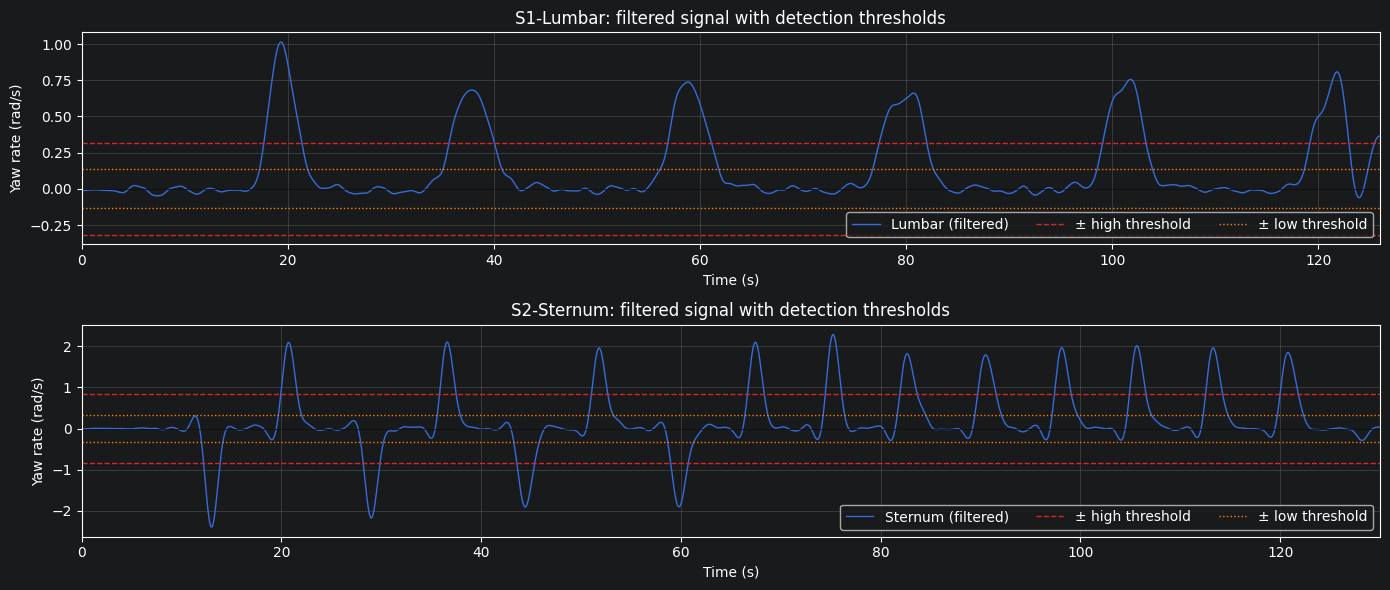

In [22]:
# --- Cell 11: Check the thresholds against the filtered trunk signals ---
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
for ax, subj in zip(axes, detect_ch):
    y = filt[subj][detect_ch[subj]]
    t = np.arange(len(y)) / fs
    th = thresholds[subj]
    ax.plot(t, y, lw=1.0, label=f"{detect_ch[subj]} (filtered)")
    for sgn in (-1, 1):
        ax.axhline(sgn * th["high"], color="tab:red", ls="--", lw=1,
                   label="\u00b1 high threshold" if sgn == 1 else None)
        ax.axhline(sgn * th["low"], color="tab:orange", ls=":", lw=1,
                   label="\u00b1 low threshold" if sgn == 1 else None)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Yaw rate (rad/s)")
    ax.set_title(f"{subj}-{detect_ch[subj]}: filtered signal with detection thresholds")
    ax.legend(loc="lower right", ncol=3)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Turn Detection on Filtered Time Signals

In [25]:
# --- Cell 12: Turn detection (hysteresis thresholding on the filtered trunk signal) ---
import pandas as pd

MIN_DURATION = 0.5    # s  - shortest event accepted as a turn
MIN_GAP = 1.0         # s  - events closer than this are merged into one turn

def detect_turns(y, th_high, th_low, fs, min_dur=MIN_DURATION, min_gap=MIN_GAP):
    """Hysteresis detector.
    1) Find runs where |y| > th_high  (confirms a turn).
    2) From each run, walk outward while y keeps the same sign and |y| > th_low  (start / end of the turn).
    3) Merge events of the same direction that overlap or are closer than min_gap; drop events shorter than min_dur.
    4) Flag events that touch the first or last sample as truncated (turn cut off by the recording).
    Returns a list of dicts with start/end sample indices, direction sign and a truncated flag."""
    N = len(y)
    above = np.abs(y) > th_high
    # rising/falling edges of the "above high threshold" mask
    d = np.diff(above.astype(int), prepend=0, append=0)
    run_starts = np.flatnonzero(d == 1)
    run_ends = np.flatnonzero(d == -1) - 1

    events = []
    for r0, r1 in zip(run_starts, run_ends):
        sgn = np.sign(y[r0:r1 + 1].sum())
        s = r0
        while s > 0 and sgn * y[s - 1] > th_low:
            s -= 1
        e = r1
        while e < N - 1 and sgn * y[e + 1] > th_low:
            e += 1
        events.append({"start": s, "end": e, "sign": int(sgn)})

    # merge same-direction events that overlap or are separated by less than min_gap
    merged = []
    for ev in sorted(events, key=lambda v: v["start"]):
        if merged and ev["sign"] == merged[-1]["sign"] and ev["start"] - merged[-1]["end"] <= min_gap * fs:
            merged[-1]["end"] = max(merged[-1]["end"], ev["end"])
        else:
            merged.append(dict(ev))

    out = []
    for ev in merged:
        if (ev["end"] - ev["start"] + 1) / fs < min_dur:
            continue
        ev["truncated"] = ev["start"] == 0 or ev["end"] == N - 1
        out.append(ev)
    return out

turns = {}        # turns[subj] -> list of detected events
turn_tables = {}  # turns[subj] -> pandas DataFrame with the results
for subj, ch in detect_ch.items():
    y = filt[subj][ch]
    x_raw = data[subj][ch]
    th = thresholds[subj]
    ev = detect_turns(y, th["high"], th["low"], fs)
    turns[subj] = ev

    rows, k = [], 0
    for e in ev:
        # rotation angle during the turn, from the RAW trunk signal (should be about +/-180 degrees)
        angle_deg = np.degrees(np.sum(x_raw[e["start"]:e["end"] + 1]) / fs)
        if not e["truncated"]:
            k += 1
        rows.append({
            "Turn": k if not e["truncated"] else "partial",
            "Start (s)": round(e["start"] / fs, 2),
            "End (s)": round(e["end"] / fs, 2),
            "Duration (s)": round((e["end"] - e["start"] + 1) / fs, 2),
            # Convention: vertical axis points up -> positive yaw rate = counter-clockwise viewed from above
            "Direction": "CCW" if e["sign"] > 0 else "CW",
            "Peak rate (rad/s)": round(y[e["start"]:e["end"] + 1][np.argmax(np.abs(y[e["start"]:e["end"] + 1]))], 2),
            "Rotation (deg)": round(angle_deg, 1),
        })
    turn_tables[subj] = pd.DataFrame(rows)

    n_full = sum(not e["truncated"] for e in ev)
    n_part = sum(e["truncated"] for e in ev)
    print(f"{subj} ({ch}): {n_full} complete turns"
          + (f", plus {n_part} partial turn(s) cut off by the start/end of the recording" if n_part else ""))
    display(turn_tables[subj])

S1 (Lumbar): 6 complete turns, plus 1 partial turn(s) cut off by the start/end of the recording


,Turn,Start (s),End (s),Duration (s),Direction,Peak rate (rad/s),Rotation (deg)
0,1,17.27,21.95,4.68,CCW,1.01,164.6
1,2,35.06,40.80,5.75,CCW,0.68,156.5
2,3,56.13,61.83,5.70,CCW,0.74,162.4
3,4,76.77,82.66,5.90,CCW,0.66,163.0
4,5,98.54,103.93,5.40,CCW,0.76,163.5
5,6,118.66,123.27,4.62,CCW,0.81,140.3
6,partial,124.83,125.99,1.17,CCW,0.37,20.8


S2 (Sternum): 15 complete turns


,Turn,Start (s),End (s),Duration (s),Direction,Peak rate (rad/s),Rotation (deg)
0,1,12.02,14.15,2.14,CW,-2.40,-172.6
1,2,19.71,22.03,2.33,CCW,2.10,166.3
2,3,27.95,30.23,2.29,CW,-2.18,-167.1
3,4,35.61,37.92,2.32,CCW,2.11,168.7
4,5,43.27,45.83,2.56,CW,-1.91,-174.1
5,6,50.78,53.25,2.48,CCW,1.96,166.9
6,7,58.69,61.30,2.62,CW,-1.91,-176.2
7,8,66.42,68.72,2.30,CCW,2.10,174.4
8,9,74.25,76.41,2.16,CCW,2.29,173.2
9,10,81.66,84.52,2.87,CCW,1.82,177.7


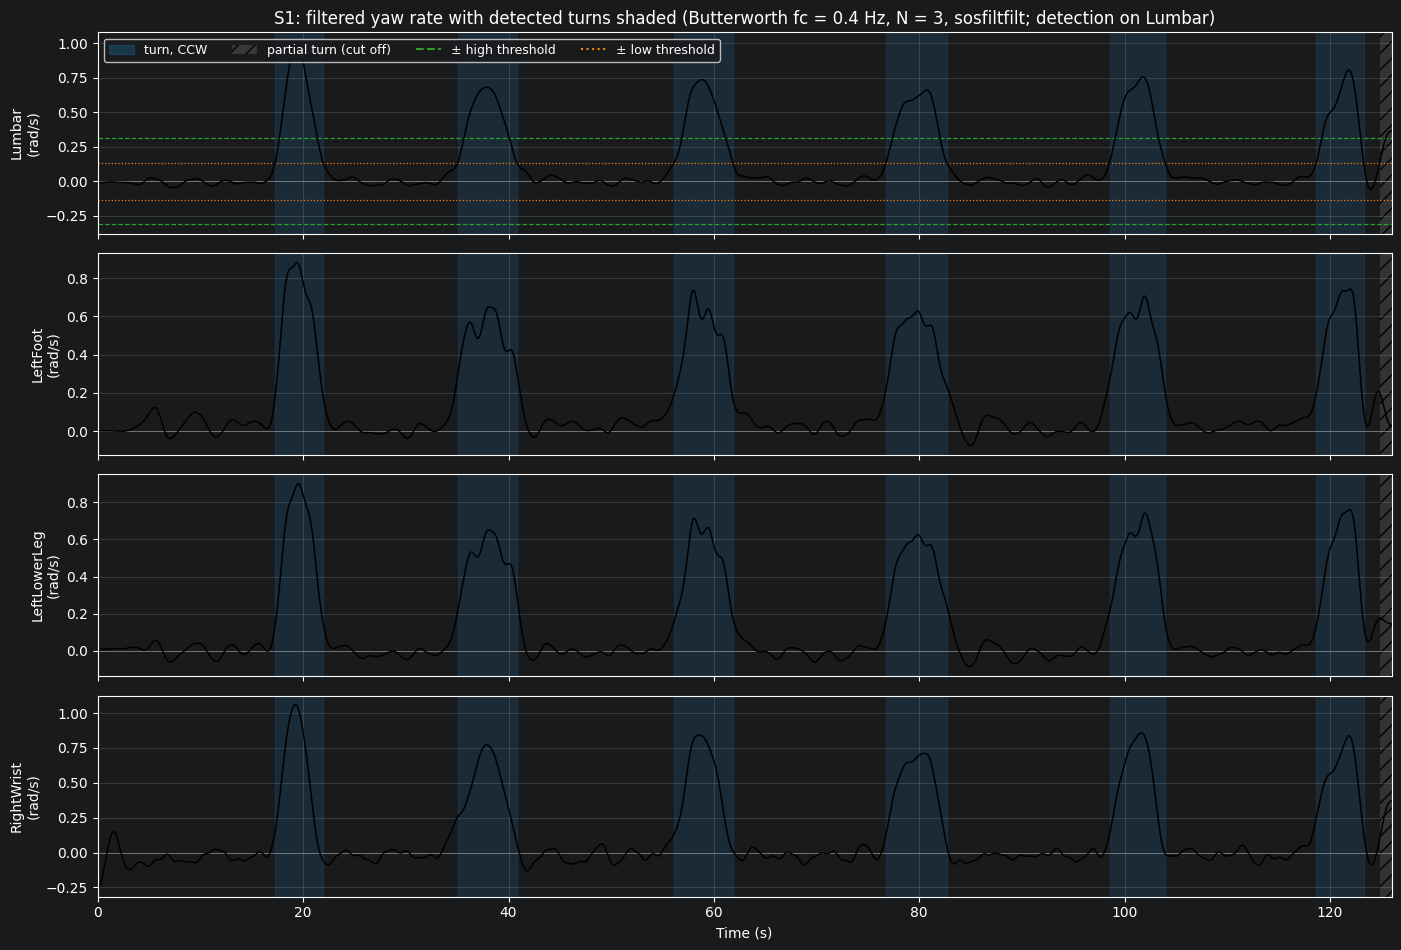

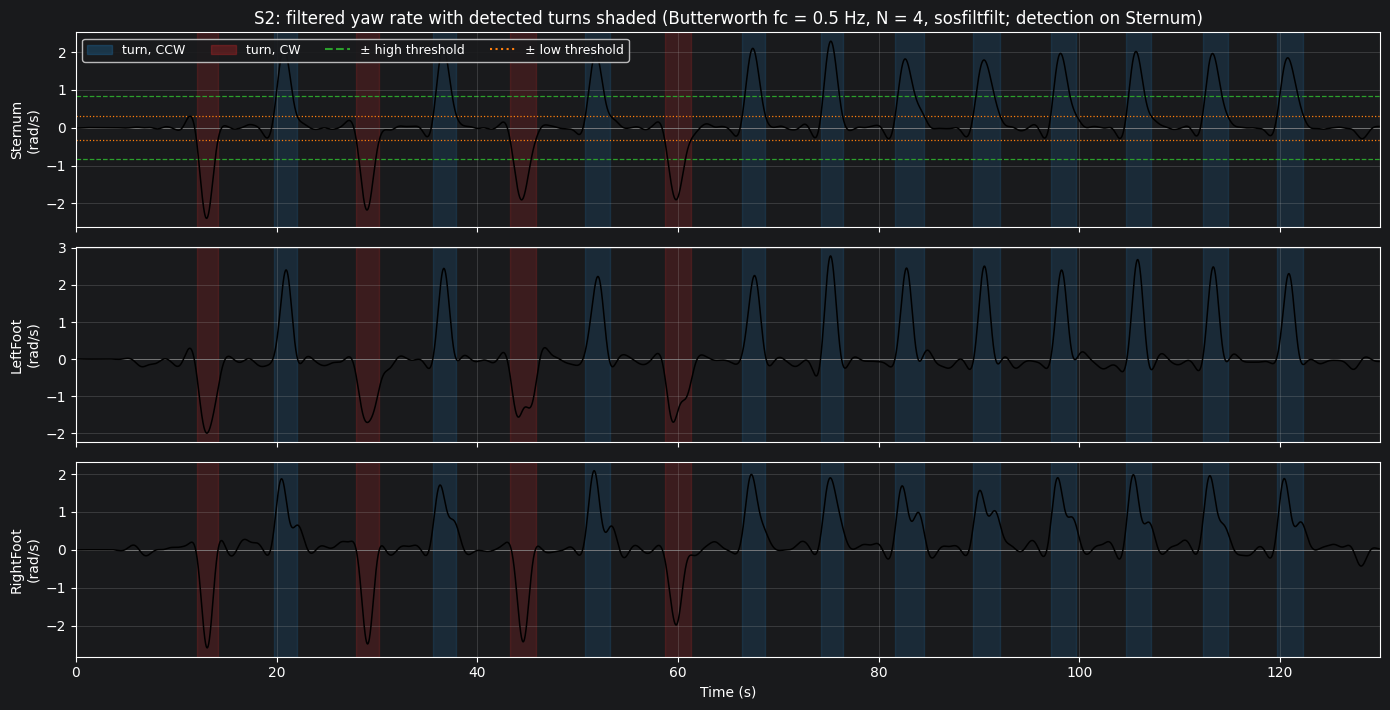

In [26]:
# --- Cell 13 (Problem 6): Filtered signals with the detected turns shaded behind every sensor ---
from matplotlib.patches import Patch

def plot_with_turns(subj, signals, title, filtered=True, show_thresholds=False):
    """signals: dict sensor -> 1-D array. Turns detected on the trunk channel are shaded on every sensor.
    Complete turns: blue = CCW, red = CW. Partial (cut off by the end of the recording): hatched gray."""
    fig, axes = plt.subplots(len(signals), 1, figsize=(14, 2.4 * len(signals)), sharex=True)
    for ax, (s, x) in zip(axes, signals.items()):
        t = np.arange(len(x)) / fs
        for e in turns[subj]:
            t0, t1 = e["start"] / fs, e["end"] / fs
            if e["truncated"]:
                ax.axvspan(t0, t1, facecolor="gray", alpha=0.25, hatch="//", zorder=0)
            else:
                ax.axvspan(t0, t1, color="tab:blue" if e["sign"] > 0 else "tab:red", alpha=0.18, zorder=0)
        ax.plot(t, x, lw=1.1 if filtered else 0.6, color="k" if filtered else "tab:blue", zorder=2)
        ax.axhline(0, color="gray", lw=0.5, zorder=1)
        if show_thresholds and s == detect_ch[subj]:
            th = thresholds[subj]
            for sgn in (-1, 1):
                ax.axhline(sgn * th["high"], color="tab:green", ls="--", lw=0.9, zorder=1)
                ax.axhline(sgn * th["low"], color="tab:orange", ls=":", lw=0.9, zorder=1)
        ax.set_ylabel(f"{s}\n(rad/s)")
        ax.set_xlim(t[0], t[-1])
        ax.grid(alpha=0.3)

    # Legend only for the shading types that actually occur
    handles = []
    if any(e["sign"] > 0 and not e["truncated"] for e in turns[subj]):
        handles.append(Patch(color="tab:blue", alpha=0.3, label="turn, CCW"))
    if any(e["sign"] < 0 and not e["truncated"] for e in turns[subj]):
        handles.append(Patch(color="tab:red", alpha=0.3, label="turn, CW"))
    if any(e["truncated"] for e in turns[subj]):
        handles.append(Patch(facecolor="gray", alpha=0.3, hatch="//", label="partial turn (cut off)"))
    if show_thresholds:
        handles += [plt.Line2D([], [], color="tab:green", ls="--", label="\u00b1 high threshold"),
                    plt.Line2D([], [], color="tab:orange", ls=":", label="\u00b1 low threshold")]
    axes[0].legend(handles=handles, loc="upper left", ncol=len(handles), fontsize=9, framealpha=0.9)
    axes[0].set_title(title)
    axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    plt.show()

for subj in filt:
    p = filter_spec[subj]
    plot_with_turns(subj, filt[subj],
                    f"{subj}: filtered yaw rate with detected turns shaded "
                    f"(Butterworth fc = {p['fc']} Hz, N = {p['N']}, sosfiltfilt; detection on {detect_ch[subj]})",
                    filtered=True, show_thresholds=True)

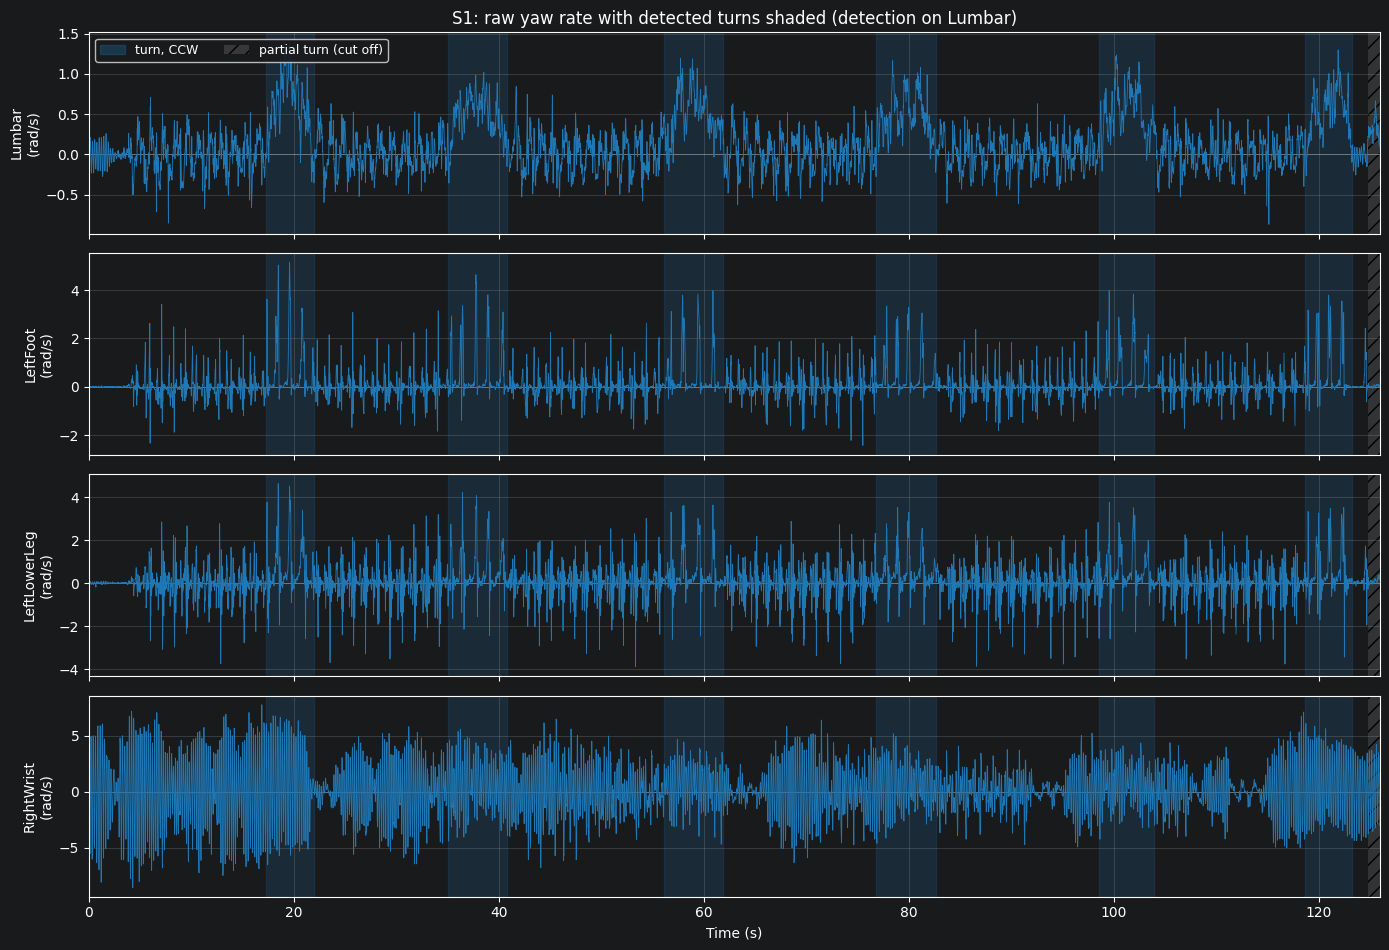

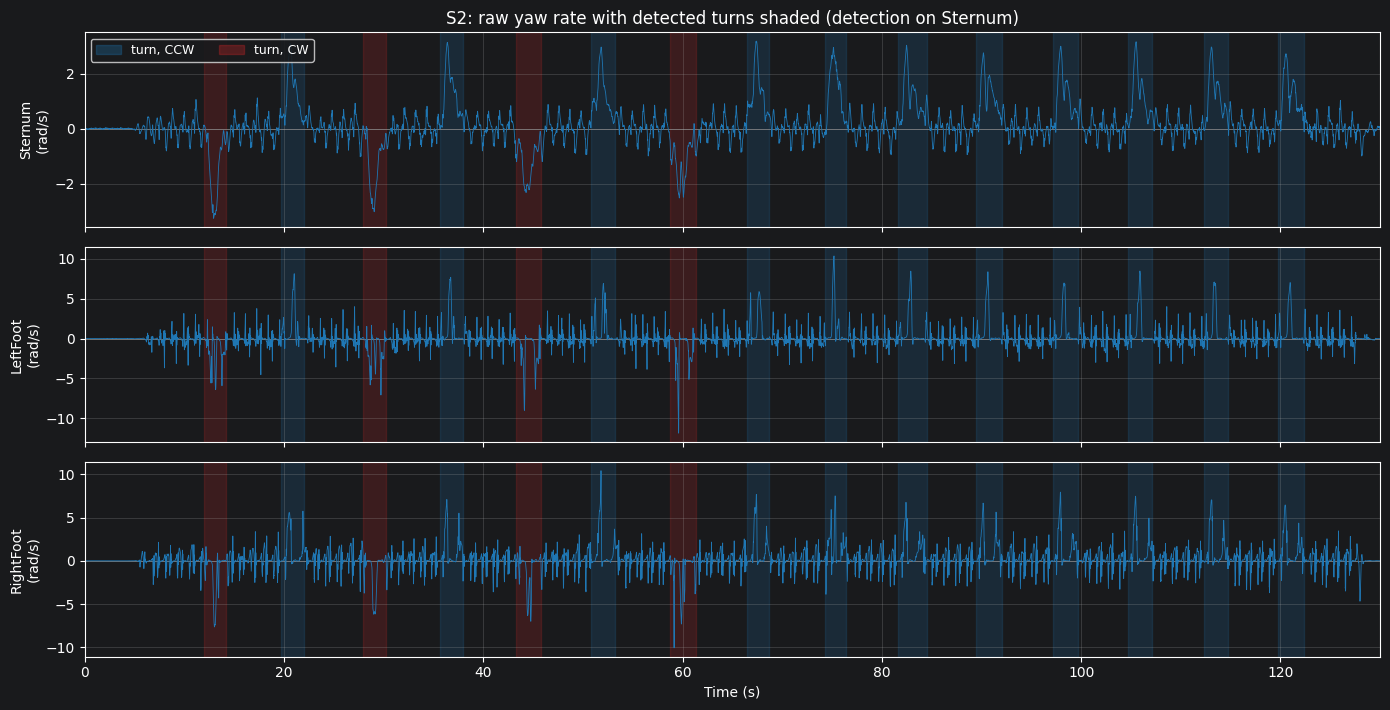

In [27]:
# --- Cell 14 (Problem 1): Raw signals with the detected turns shaded behind every sensor ---
for subj in data:
    plot_with_turns(subj, data[subj],
                    f"{subj}: raw yaw rate with detected turns shaded (detection on {detect_ch[subj]})",
                    filtered=False)

## Problem 3: Plot the impulse response of your filter.

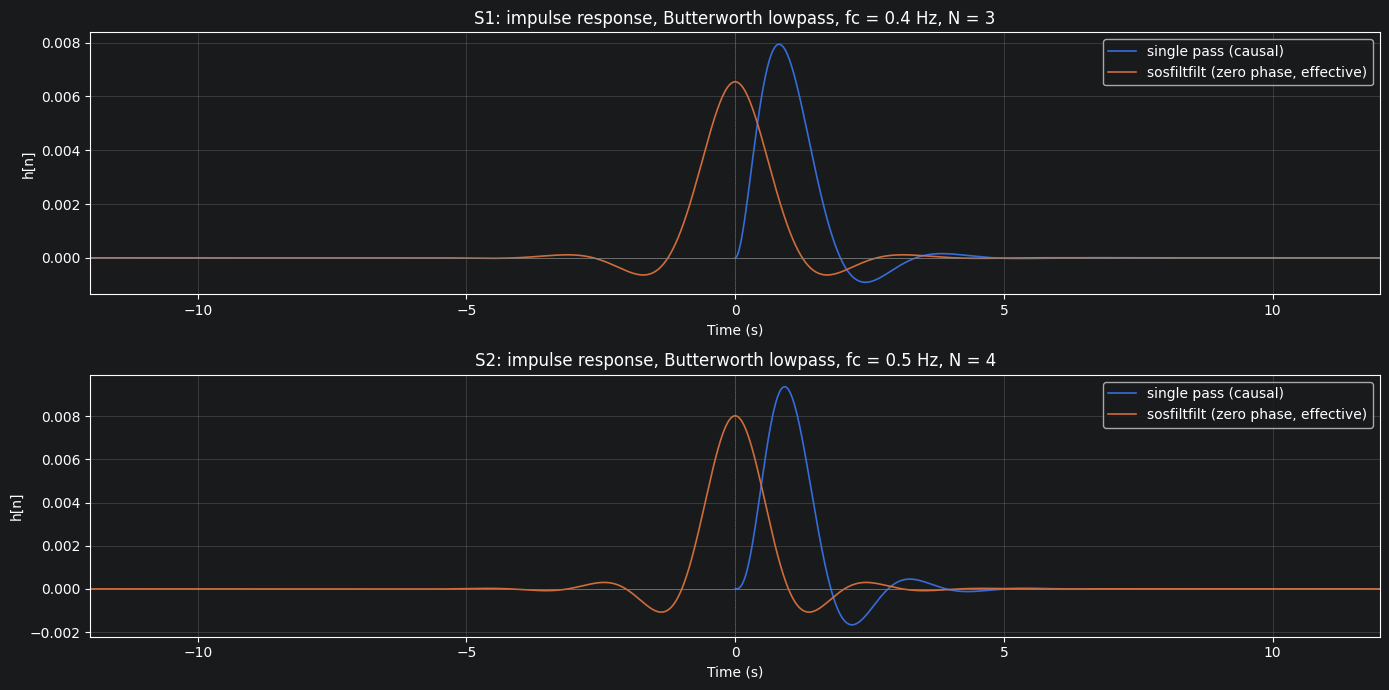

In [17]:
# --- Cell 6: Impulse response (single pass vs. effective zero-phase sosfiltfilt) ---
T_imp = 12.0  # seconds shown on each side
n_half = int(T_imp * fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, subj in zip(axes, filter_spec):
    p = filter_spec[subj]

    # Single pass (causal): impulse at n = 0
    d = np.zeros(n_half + 1);
    d[0] = 1.0
    h1 = sosfilt(sos[subj], d)
    t1 = np.arange(len(h1)) / fs

    # Effective sosfiltfilt response (non-causal, symmetric): impulse in the middle of a long buffer
    d2 = np.zeros(2 * n_half + 1);
    d2[n_half] = 1.0
    h2 = sosfiltfilt(sos[subj], d2)
    t2 = (np.arange(len(h2)) - n_half) / fs

    ax.plot(t1, h1, lw=1.2, label="single pass (causal)")
    ax.plot(t2, h2, lw=1.2, label="sosfiltfilt (zero phase, effective)")
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5, ls=":")
    ax.set_xlim(-T_imp, T_imp)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("h[n]")
    ax.set_title(f"{subj}: impulse response, Butterworth lowpass, fc = {p['fc']} Hz, N = {p['N']}")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Problem 4: Plot the magnitude response of your filter.

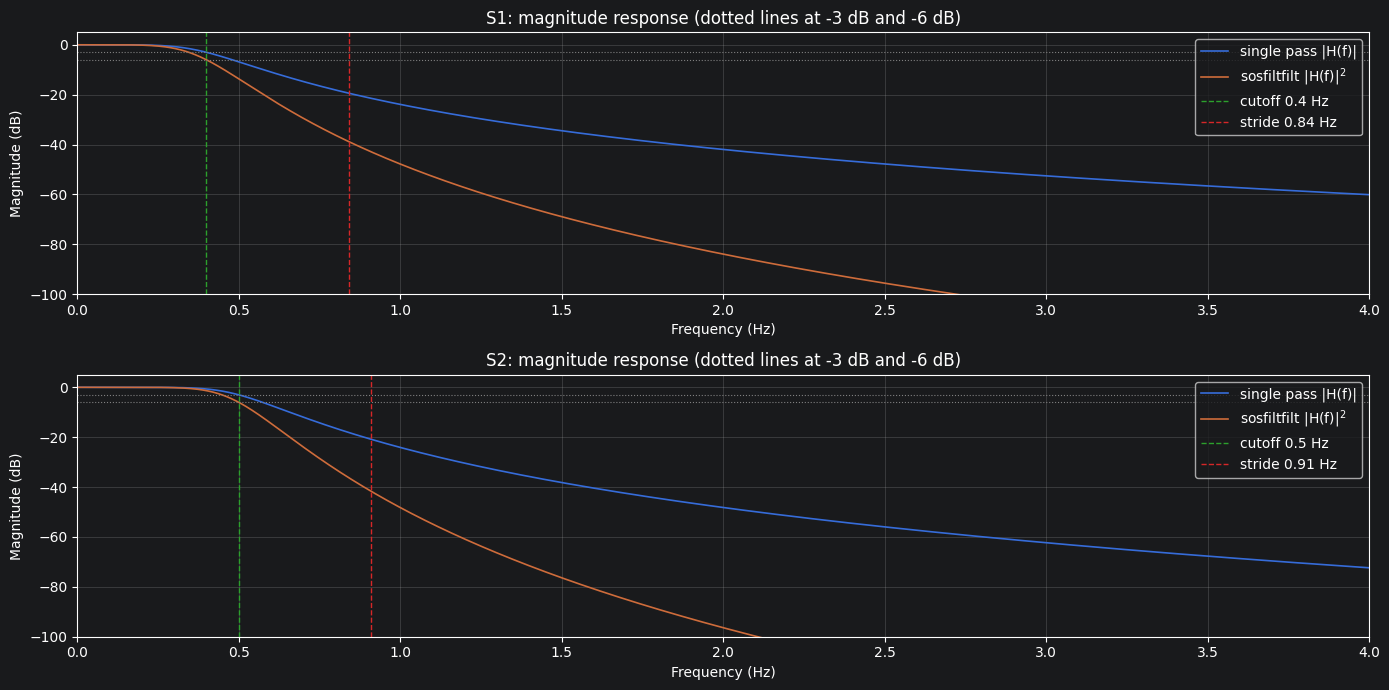

In [18]:
# --- Cell 7: Magnitude response ---
f_resp = np.linspace(0, 4.0, 4000)  # Hz; zoomed to the band that matters
f_resp[0] = 1e-6  # avoid exactly 0 Hz

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, subj in zip(axes, filter_spec):
    p = filter_spec[subj]
    _, H = sosfreqz(sos[subj], worN=f_resp, fs=fs)
    mag1 = 20 * np.log10(np.abs(H) + 1e-300)  # single pass
    mag2 = 2 * mag1  # sosfiltfilt: |H|^2

    ax.plot(f_resp, mag1, lw=1.2, label="single pass |H(f)|")
    ax.plot(f_resp, mag2, lw=1.2, label="sosfiltfilt |H(f)|$^2$")
    ax.axvline(p["fc"], color="tab:green", ls="--", lw=1, label=f"cutoff {p['fc']} Hz")
    ax.axvline(p["f_stride"], color="tab:red", ls="--", lw=1, label=f"stride {p['f_stride']} Hz")
    ax.axhline(-3, color="gray", ls=":", lw=0.8)
    ax.axhline(-6, color="gray", ls=":", lw=0.8)
    ax.set_xlim(0, f_resp[-1])
    ax.set_ylim(-100, 5)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Magnitude (dB)")
    ax.set_title(f"{subj}: magnitude response (dotted lines at -3 dB and -6 dB)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Problem 5: Plot the phase response of your filter.

S1: single-pass group delay near DC = 0.80 s (sosfiltfilt removes this delay)
S2: single-pass group delay near DC = 0.83 s (sosfiltfilt removes this delay)


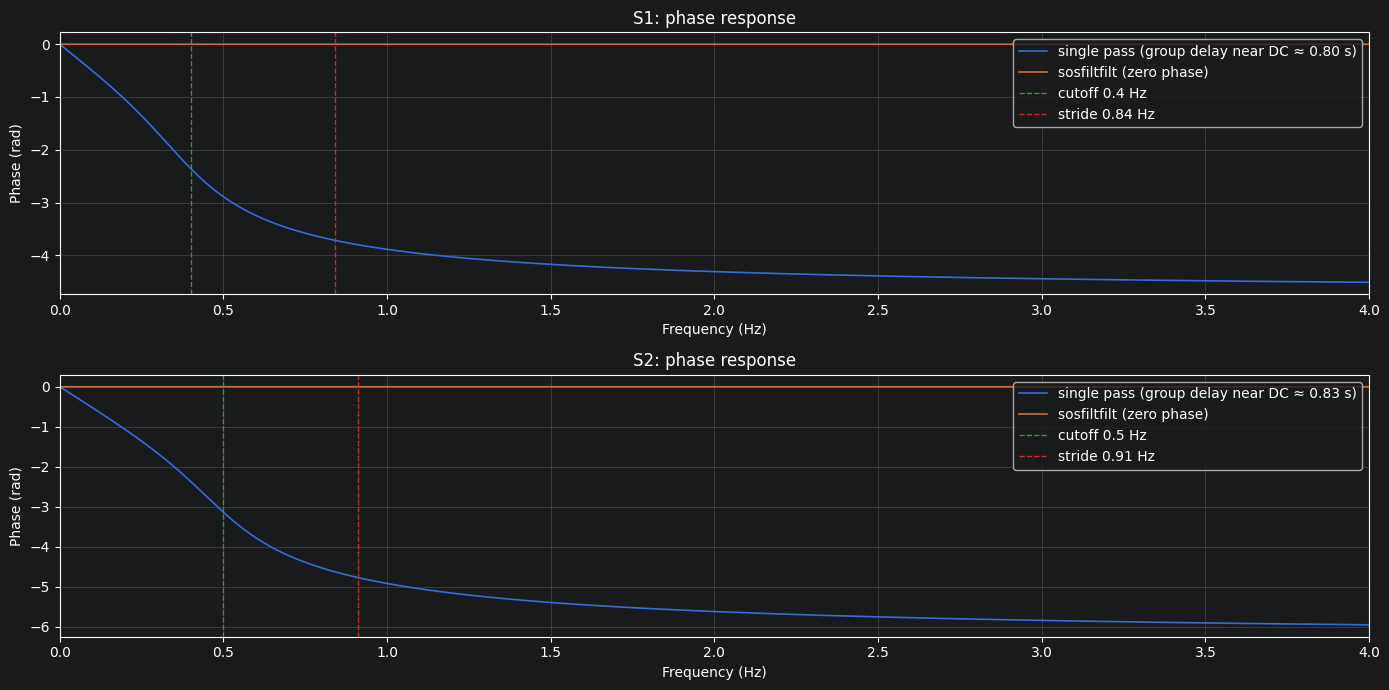

In [19]:
# --- Cell 8: Phase response ---
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, subj in zip(axes, filter_spec):
    p = filter_spec[subj]
    _, H = sosfreqz(sos[subj], worN=f_resp, fs=fs)
    phase1 = np.unwrap(np.angle(H))  # single pass (rad)

    # Group delay near DC = -d(phase)/d(omega), omega = 2*pi*f
    gd = -np.gradient(phase1, 2 * np.pi * f_resp)
    gd_dc = gd[f_resp < 0.05].mean()

    ax.plot(f_resp, phase1, lw=1.2, label=f"single pass (group delay near DC \u2248 {gd_dc:.2f} s)")
    ax.plot(f_resp, np.zeros_like(f_resp), lw=1.2, label="sosfiltfilt (zero phase)")
    ax.axvline(p["fc"], color="tab:green", ls="--", lw=1, label=f"cutoff {p['fc']} Hz")
    ax.axvline(p["f_stride"], color="tab:red", ls="--", lw=1, label=f"stride {p['f_stride']} Hz")
    ax.set_xlim(0, f_resp[-1])
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Phase (rad)")
    ax.set_title(f"{subj}: phase response")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    print(f"{subj}: single-pass group delay near DC = {gd_dc:.2f} s "
          f"(sosfiltfilt removes this delay)")
fig.tight_layout()
plt.show()

## Problem 6: Include time-domain plots of the filtered signals

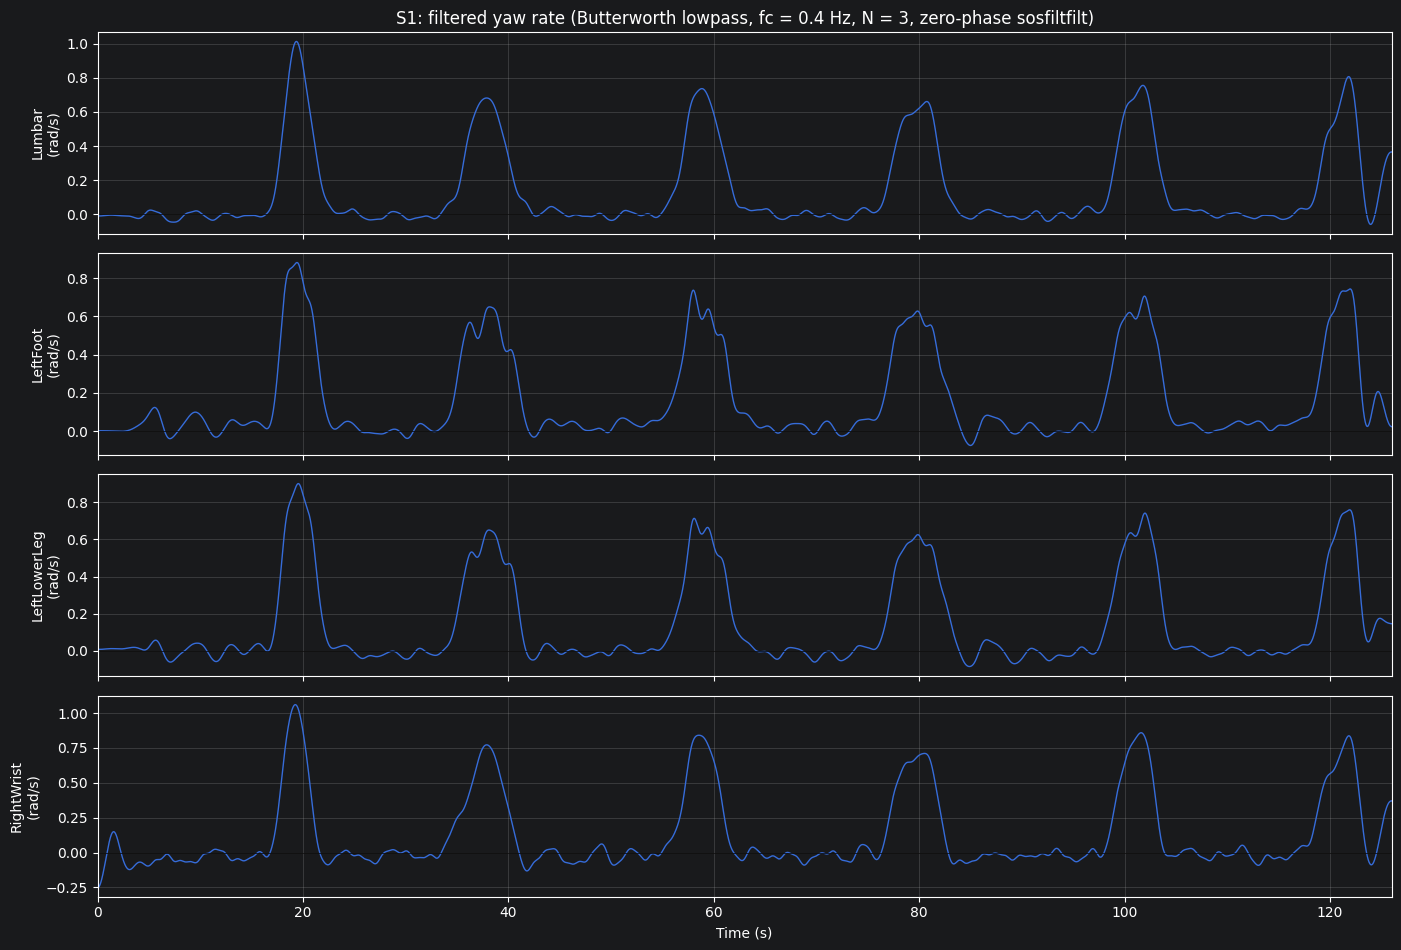

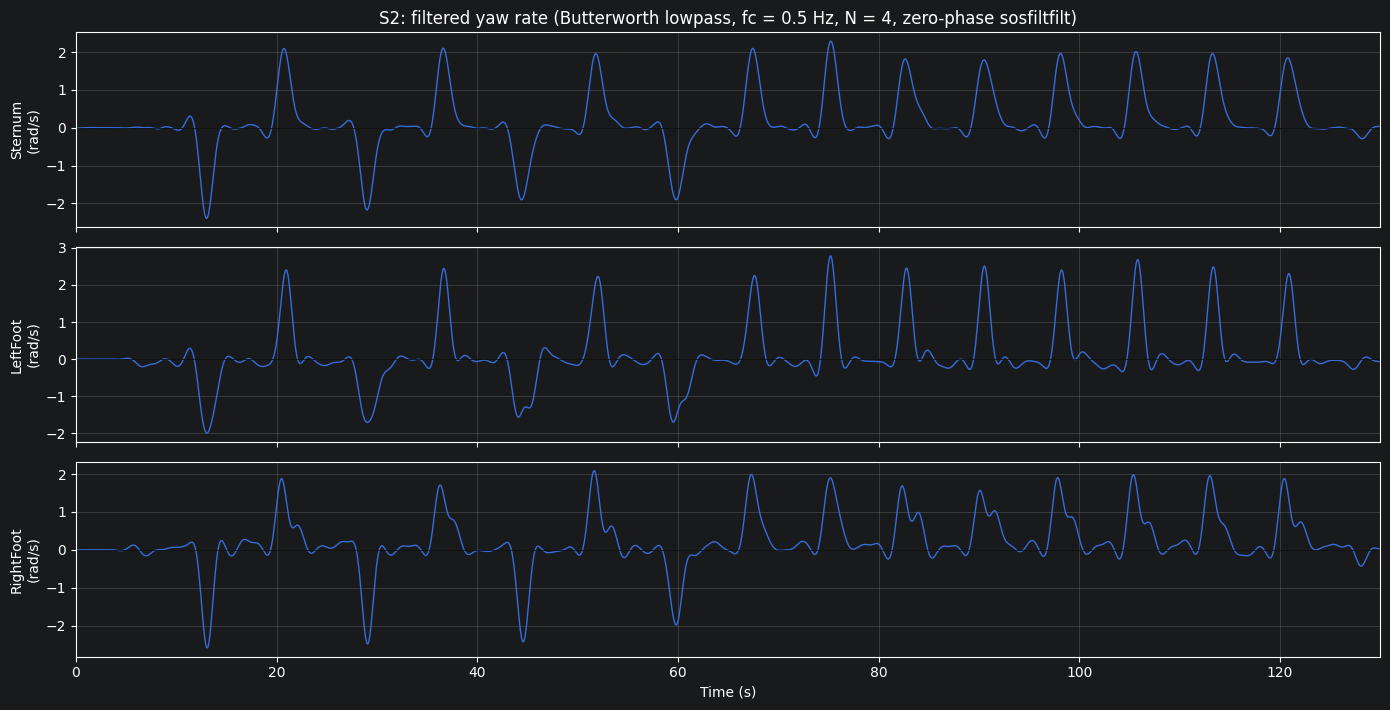

In [20]:
# --- Cell 9: Apply each subject's filter to all of that subject's sensors and plot ---
# Edge handling: mirror ("even") padding of 4 s at each end. The default odd padding reflects about the
# first/last sample, which creates a large start-up transient when a channel starts mid-swing (e.g. the wrist).
PADLEN = int(4 * fs)


def apply_filter(subj, x):
    return sosfiltfilt(sos[subj], x, padtype="even", padlen=PADLEN)


filt = {subj: {s: apply_filter(subj, x) for s, x in sig.items()} for subj, sig in data.items()}


def plot_filtered(subj):
    sig = filt[subj]
    p = filter_spec[subj]
    fig, axes = plt.subplots(len(sig), 1, figsize=(14, 2.4 * len(sig)), sharex=True)
    for ax, (s, y) in zip(axes, sig.items()):
        t = np.arange(len(y)) / fs
        ax.plot(t, y, lw=1.0)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_ylabel(f"{s}\n(rad/s)")
        ax.set_xlim(t[0], t[-1])
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{subj}: filtered yaw rate (Butterworth lowpass, fc = {p['fc']} Hz, "
                      f"N = {p['N']}, zero-phase sosfiltfilt)")
    axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    plt.show()


for subj in filt:
    plot_filtered(subj)

## Problem 7: If you combine the signals from each subject in some manner to detect the turns more accurately, explain how you combined the signals and state your rationale for this decision.

### Decision
I did **not** average or otherwise combine the sensors into one detection signal. Turns were detected on **one trunk sensor per subject**: **Lumbar** for S1 and **Sternum** for S2. The sensors are synchronized, so the start and end times from the trunk were then **shaded on every sensor** of that subject. The other sensors were used to visually **check** the detections, not to make them.

### Rationale

**1. The trunk measures the quantity we want, whole-body rotation.** In a 180° turn the entire body rotates, and the trunk carries that rotation directly. The limbs add their own motion on top of it:
- **Feet and lower leg:** the foot rotates in short pivots while planted and is still between steps, so its signal is a train of spikes rather than a smooth turn.
- **Wrist:** a large oscillation of about ±5–8 rad/s near **4.6 Hz**, unrelated to the gait cycle or the turns.

**2. The total heading shows the trunk is the most reliable measure of turning.** Integrating each raw signal gives its total heading change over the recording:

| Sensor | Total heading | Sensor | Total heading |
|---|---|---|---|
| S1-Lumbar | 17.3 rad (5.5π) | S2-Sternum | 20.9 rad (6.7π) |
| S1-LeftLowerLeg | 17.7 rad (5.6π) | S2-LeftFoot | 13.8 rad (4.4π) |
| S1-LeftFoot | 20.6 rad (6.6π) | S2-RightFoot | 25.2 rad (8.0π) |
| S1-RightWrist | 15.8 rad (5.0π) | | |

The expected net rotation is 6 × π for S1 and (11 − 4) × π = 7π for S2. The trunk sensors come close. The feet over- or under-rotate by up to about 1.6π, and S2's two feet disagree with each other by about 3.6π. Averaging in the limb sensors would add these errors to the trunk signal and make the turn edges and rotation angles less accurate.

**3. Every sensor confirms the trunk detections.** I ran the same detector (Otsu high threshold, 3σ̂ low threshold, same filter) on each sensor by itself:

| Subject | Sensor | Complete turns | Direction sequence |
|---|---|---|---|
| S1 | Lumbar, LeftFoot, LeftLowerLeg, RightWrist | 6 on every sensor | CCW ×6 on every sensor |
| S2 | Sternum, LeftFoot, RightFoot | 15 on every sensor | CW, CCW, CW, CCW, CW, CCW, CW, then CCW ×8, on every sensor |

Because every sensor already gives the same count and the same directions, combining them could not have improved those results. The only thing combining could change is exactly where each turn starts and ends, and there the trunk is the best single reference, for the reasons in points 1 and 2.

**4. The trunk alone gives a clean signal for detection.** On the filtered trunk signal, the walking samples and the turning samples form two clearly separate groups in the histogram (see the Otsu section). Every turn crosses the high threshold, and no stretch of straight walking does. There was no ambiguity for a combined signal to resolve.

**5. A single channel is simpler, and easier to defend, than a combination.** A combined signal needs weights, and the sensors differ widely in amplitude (the wrist's standard deviation is about 8× the lumbar's). The weights would also have to be chosen separately for each subject, because the subjects wear different sensors. Using one trunk sensor avoids those arbitrary choices.

### If the trunk sensor were unavailable
The comparison suggests a workable alternative. For S2, the **average of the left and right foot** reaches a total heading of about 19.5 rad, close to the sternum's 20.9 rad, because the two feet's errors partly cancel. Averaging both feet would be a reasonable combination for a subject with no trunk sensor. Using the wrist alone would be the weakest choice.

## Problem 8: Explain how you identified the beginning and end of each turn.

### Detection channel
Turns were detected on **one channel per subject**: the filtered trunk sensor (**Lumbar** for S1, **Sternum** for S2). The trunk rotates with the whole body during a turn. The heading plots show it tracking body orientation most closely, and the feet and wrist add extra motion (foot pivots, a 4.6 Hz wrist oscillation). The start and end times found on the trunk channel were then shaded on every sensor of that subject. The sensors are synchronized, so one set of turn times applies to all of them.

### Method: hysteresis thresholding on the filtered signal
1. **Filter.** Remove the stride and arm components with the subject's zero-phase Butterworth lowpass (S1: $f_c$ = 0.40 Hz, N = 3; S2: $f_c$ = 0.5 Hz, N = 4; `sosfiltfilt`). Because the filter is zero-phase, the turn edges are **not delayed**. A single forward pass would have shifted every edge by about 0.8 s.
2. **Choose two thresholds from the data** (see the Otsu section):
   - **High threshold** $T_H$ = the Otsu threshold of $|y|$: **0.31 rad/s (S1)** and **0.84 rad/s (S2)**. This separates "turning" from "not turning."
   - **Low threshold** $T_L = 3\hat\sigma$, where $\hat\sigma = 1.4826\cdot\text{MAD}$ is the walking-noise level: **0.13 rad/s (S1)** and **0.32 rad/s (S2)**. This sits just above the noise during straight walking.
3. **Confirm a turn.** Each continuous run where $|y[n]| > T_H$ marks one turn. The sign of $y$ in that run gives its direction.
4. **Find the start and end.** From the run, move **backward** sample by sample while $y$ has the same sign and $|y| > T_L$. The first sample of the turn is the **start**. Move **forward** the same way. The last sample is the **end**. Requiring the same sign keeps a turn from running into a neighboring turn in the opposite direction, which matters for S2's alternating turns.
5. **Clean up the events.** Same-direction events less than **1.0 s** apart are merged into one turn, so a brief dip during a turn can't split it in two. Events shorter than **0.5 s** are discarded. None were discarded in this data.
6. **Edges of the recording.** An event that touches the first or last sample is marked **partial**, because the turn was cut off by the recording. It is shaded with gray hatching and not counted. This happens once, at the end of S1 (124.8–126.0 s).

### Why hysteresis (two thresholds)?
- A **single high threshold** would mark the edges too late and too early. Turns would come out too short, because the slow ramp at the start and end of each turn is below $T_H$.
- A **single low threshold** would be too sensitive. Small leftover wiggles from walking could cross it and create false turns.
- With two thresholds, the high one decides **whether** a turn happened, and the low one decides **when** it started and ended.

### Duration and direction
- **Duration** $= (n_\text{end} - n_\text{start} + 1)/f_s$ seconds.
- **Direction:** positive yaw rate = **counter-clockwise (CCW)** viewed from above, negative = **clockwise (CW)**. This assumes the sensor's vertical axis points **up** (right-hand rule). The assignment does not state the axis direction. If it points down, every direction is reversed.

### Validation
- **Rotation check:** integrating the *raw* trunk yaw rate between each start and end gives the angle turned. The results are about **156–165° (S1)** and **166–178° (S2)**, close to the expected 180°. The values fall a little short of 180° because the slow tails below $T_L$ are left out, and S1 tends to turn slightly less than 180°. S1's last complete turn (140°) is followed by the partial turn at the end of the recording.
- **Consistency across sensors:** the shaded regions found on the trunk line up with the turn bumps on every other filtered sensor, including the feet, the lower leg, and the wrist.

### Limitation
The lowpass filter spreads each turn slightly in time, so durations measured on the filtered signal are a little **longer** than the actual turns. The effect is largest for S1, which has the lower cutoff. Because the same method is used for every turn, the durations can still be compared with one another.

## Problem 9: For each subject report:
* How many 180 degree turns were included in this recording?
* What was the direction of each turn? Clockwise or counter clockwise?
* What was the duration of each turn in units of seconds?

In [28]:
# --- Cell 12: Turn detection (hysteresis thresholding on the filtered trunk signal) ---
import pandas as pd

MIN_DURATION = 0.5  # s  - shortest event accepted as a turn
MIN_GAP = 1.0  # s  - events closer than this are merged into one turn


def detect_turns(y, th_high, th_low, fs, min_dur=MIN_DURATION, min_gap=MIN_GAP):
    """Hysteresis detector.
    1) Find runs where |y| > th_high  (confirms a turn).
    2) From each run, walk outward while y keeps the same sign and |y| > th_low  (start / end of the turn).
    3) Merge events of the same direction that overlap or are closer than min_gap; drop events shorter than min_dur.
    4) Flag events that touch the first or last sample as truncated (turn cut off by the recording).
    Returns a list of dicts with start/end sample indices, direction sign and a truncated flag."""
    N = len(y)
    above = np.abs(y) > th_high
    # rising/falling edges of the "above high threshold" mask
    d = np.diff(above.astype(int), prepend=0, append=0)
    run_starts = np.flatnonzero(d == 1)
    run_ends = np.flatnonzero(d == -1) - 1

    events = []
    for r0, r1 in zip(run_starts, run_ends):
        sgn = np.sign(y[r0:r1 + 1].sum())
        s = r0
        while s > 0 and sgn * y[s - 1] > th_low:
            s -= 1
        e = r1
        while e < N - 1 and sgn * y[e + 1] > th_low:
            e += 1
        events.append({"start": s, "end": e, "sign": int(sgn)})

    # merge same-direction events that overlap or are separated by less than min_gap
    merged = []
    for ev in sorted(events, key=lambda v: v["start"]):
        if merged and ev["sign"] == merged[-1]["sign"] and ev["start"] - merged[-1]["end"] <= min_gap * fs:
            merged[-1]["end"] = max(merged[-1]["end"], ev["end"])
        else:
            merged.append(dict(ev))

    out = []
    for ev in merged:
        if (ev["end"] - ev["start"] + 1) / fs < min_dur:
            continue
        ev["truncated"] = ev["start"] == 0 or ev["end"] == N - 1
        out.append(ev)
    return out


turns = {}  # turns[subj] -> list of detected events
turn_tables = {}  # turns[subj] -> pandas DataFrame with the results
for subj, ch in detect_ch.items():
    y = filt[subj][ch]
    x_raw = data[subj][ch]
    th = thresholds[subj]
    ev = detect_turns(y, th["high"], th["low"], fs)
    turns[subj] = ev

    rows, k = [], 0
    for e in ev:
        # rotation angle during the turn, from the RAW trunk signal (should be about +/-180 degrees)
        angle_deg = np.degrees(np.sum(x_raw[e["start"]:e["end"] + 1]) / fs)
        if not e["truncated"]:
            k += 1
        rows.append({
            "Turn": k if not e["truncated"] else "partial",
            "Start (s)": round(e["start"] / fs, 2),
            "End (s)": round(e["end"] / fs, 2),
            "Duration (s)": round((e["end"] - e["start"] + 1) / fs, 2),
            # Convention: vertical axis points up -> positive yaw rate = counter-clockwise viewed from above
            "Direction": "CCW" if e["sign"] > 0 else "CW",
            "Peak rate (rad/s)": round(y[e["start"]:e["end"] + 1][np.argmax(np.abs(y[e["start"]:e["end"] + 1]))], 2),
            "Rotation (deg)": round(angle_deg, 1),
        })
    turn_tables[subj] = pd.DataFrame(rows)

    n_full = sum(not e["truncated"] for e in ev)
    n_part = sum(e["truncated"] for e in ev)
    print(f"{subj} ({ch}): {n_full} complete turns"
          + (f", plus {n_part} partial turn(s) cut off by the start/end of the recording" if n_part else ""))
    display(turn_tables[subj])

S1 (Lumbar): 6 complete turns, plus 1 partial turn(s) cut off by the start/end of the recording


,Turn,Start (s),End (s),Duration (s),Direction,Peak rate (rad/s),Rotation (deg)
0,1,17.27,21.95,4.68,CCW,1.01,164.6
1,2,35.06,40.80,5.75,CCW,0.68,156.5
2,3,56.13,61.83,5.70,CCW,0.74,162.4
3,4,76.77,82.66,5.90,CCW,0.66,163.0
4,5,98.54,103.93,5.40,CCW,0.76,163.5
5,6,118.66,123.27,4.62,CCW,0.81,140.3
6,partial,124.83,125.99,1.17,CCW,0.37,20.8


S2 (Sternum): 15 complete turns


,Turn,Start (s),End (s),Duration (s),Direction,Peak rate (rad/s),Rotation (deg)
0,1,12.02,14.15,2.14,CW,-2.40,-172.6
1,2,19.71,22.03,2.33,CCW,2.10,166.3
2,3,27.95,30.23,2.29,CW,-2.18,-167.1
3,4,35.61,37.92,2.32,CCW,2.11,168.7
4,5,43.27,45.83,2.56,CW,-1.91,-174.1
5,6,50.78,53.25,2.48,CCW,1.96,166.9
6,7,58.69,61.30,2.62,CW,-1.91,-176.2
7,8,66.42,68.72,2.30,CCW,2.10,174.4
8,9,74.25,76.41,2.16,CCW,2.29,173.2
9,10,81.66,84.52,2.87,CCW,1.82,177.7


## Problem 1: Include time domain plot of all of the signals for each subject. Indicate the start and end of each turn as a shaded region behind the signals.

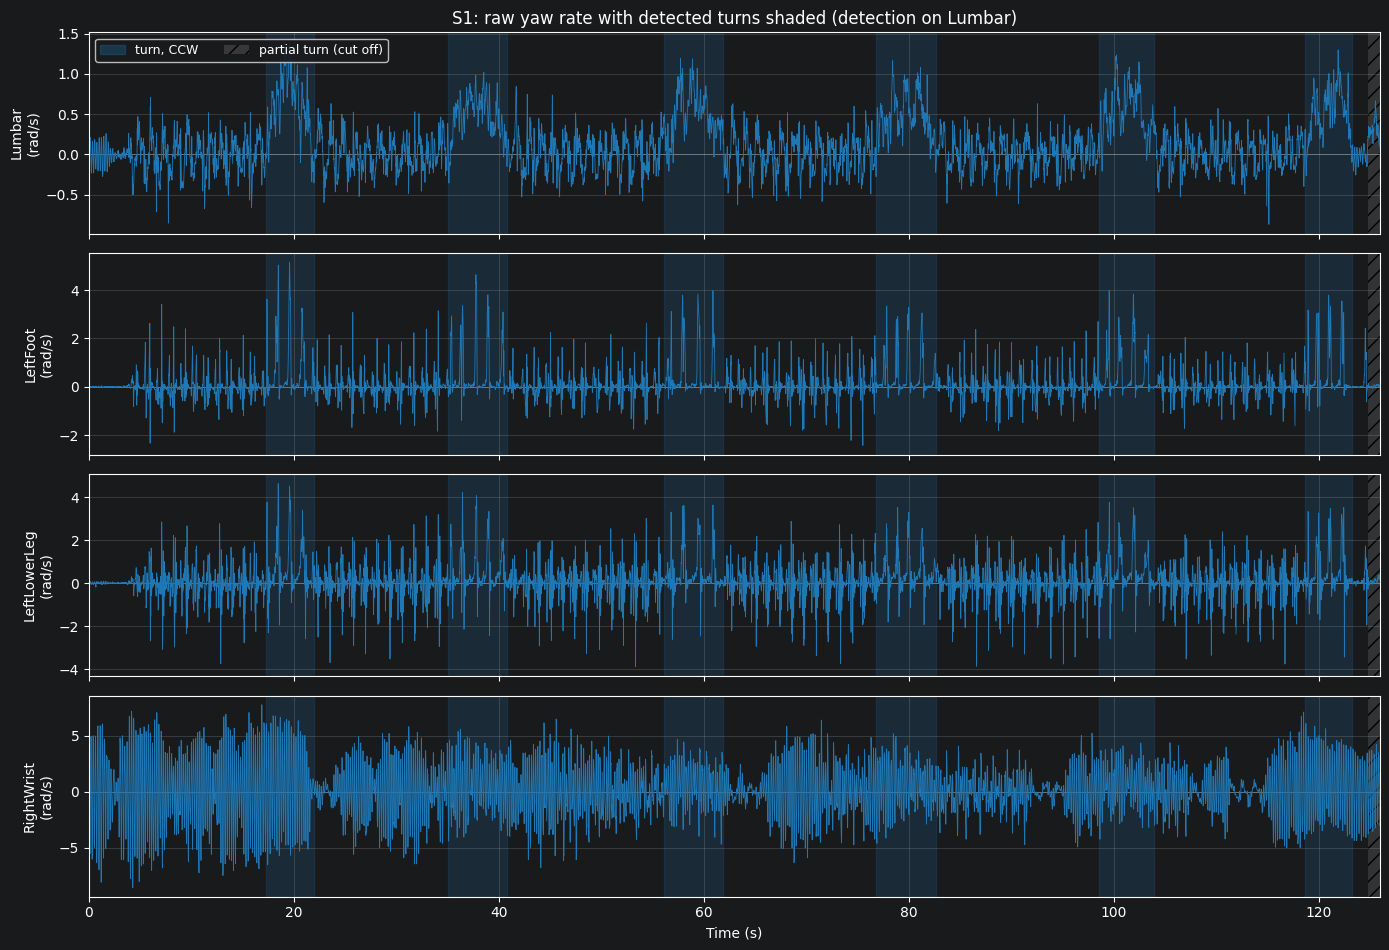

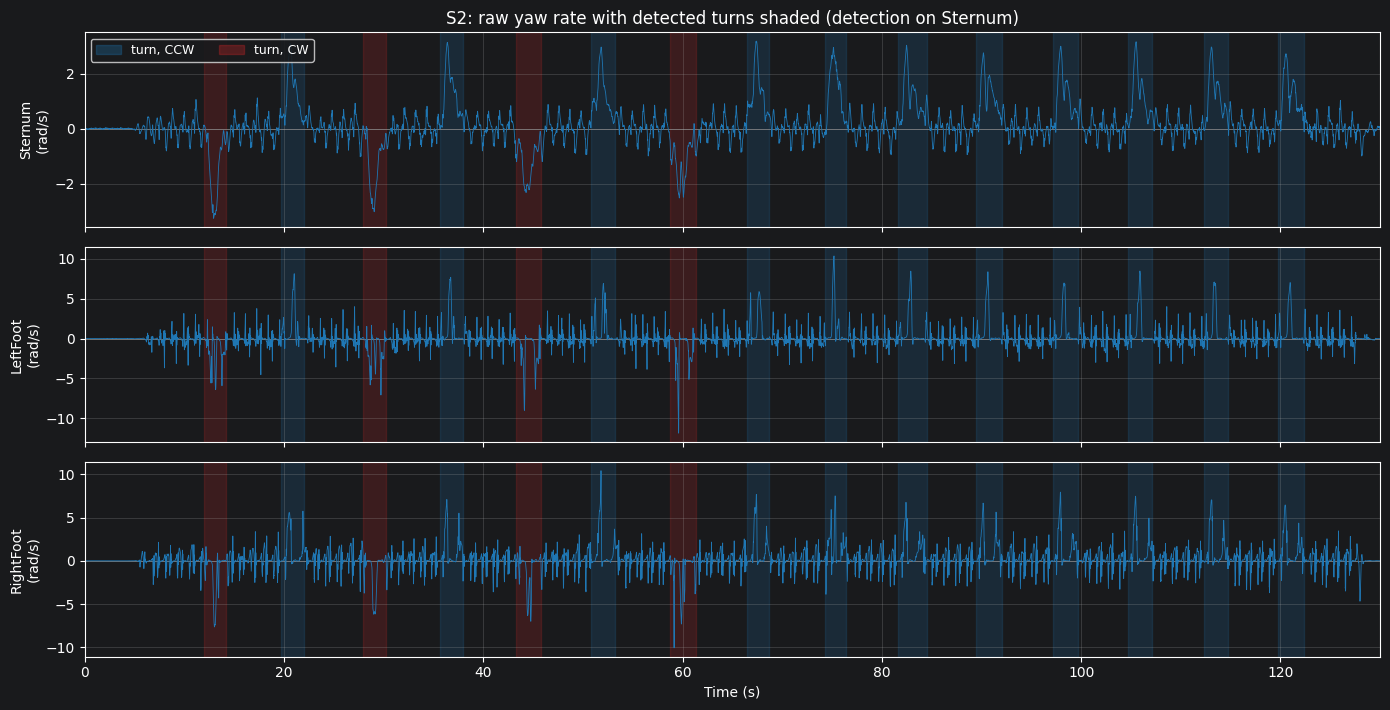

In [29]:
# --- Cell 14 (Problem 1): Raw signals with the detected turns shaded behind every sensor ---
for subj in data:
    plot_with_turns(subj, data[subj],
                    f"{subj}: raw yaw rate with detected turns shaded (detection on {detect_ch[subj]})",
                    filtered=False)

## Problem 10: What, if anything, did you learn from this homework?

**1. When to use `sosfiltfilt` vs. `filtfilt`.**
Both run an IIR filter forward and then backward, so the result has zero phase, the magnitude response is squared, and the effective order doubles. `filtfilt` works from transfer-function coefficients $(b, a)$. When the cutoff is very low relative to the sample rate, the poles bunch up near $z = 1$, and small rounding errors in those polynomial coefficients can make the filter inaccurate or even unstable. `sosfiltfilt` implements the same filter as a cascade of second-order sections, which stays numerically stable. My cutoffs (0.40 Hz and 0.5 Hz at $f_s$ = 128 Hz) are below 1% of the Nyquist frequency, so I used `butter(..., output="sos")` with `sosfiltfilt`. I also learned that edge padding matters: the default odd padding caused a false spike of about 7 rad/s at the start of the S1 wrist signal, and switching to mirror ("even") padding removed it.

**2. Using running integrals to find turns and measure their size.**
Integrating yaw rate gives heading angle, $\theta[n] = \frac{1}{f_s}\sum_{k \le n} \omega[k]$. In the heading plot, each 180° turn appears as a step of about $\pm\pi$ rad, while straight walking stays roughly flat. Plotting the heading before designing anything showed that the nonzero mean of each signal came from real turning, not sensor bias. That told me not to subtract the mean. Integrating the raw trunk signal between each detected start and end also gave the angle of each turn: about 156–165° for S1 and 166–178° for S2. That served as a check that each detection was a real turn.

**3. Otsu's thresholding method.**
Otsu's method picks the threshold that best splits a histogram into two classes, by maximizing the between-class variance $\sigma_B^2(k) = w_0 w_1(\mu_0 - \mu_1)^2$ over every candidate threshold $k$. It uses only the data and has no tuning parameters. I applied it to the histogram of $|y|$, the filtered trunk signal, where the two classes are walking (a spike near 0) and turning (a smaller cluster farther out). The resulting high thresholds were 0.31 rad/s for S1 and 0.84 rad/s for S2. Plotting the $\sigma_B^2$ curve showed a broad, flat peak, which means the detection is not sensitive to the exact threshold value.

**4. Between-class (inter-class) vs. within-class (intra-class) variance.**
The total variance of a dataset splits exactly into two parts: $\sigma_T^2 = \sigma_W^2 + \sigma_B^2$. The within-class part, $\sigma_W^2$, measures how spread out each class is around its own mean. The between-class part, $\sigma_B^2$, measures how far apart the two class means are. Because $\sigma_T^2$ is the same whatever threshold is chosen, maximizing $\sigma_B^2$ is the same as minimizing $\sigma_W^2$. That is why Otsu's threshold gives two compact, well-separated groups: here, "walking" and "turning."

**5. Median absolute deviation (MAD).**
The MAD, $\text{median}(|y - \text{median}(y)|)$, is a robust measure of spread. Multiplying it by $1.4826 = 1/\Phi^{-1}(0.75)$ turns it into an estimate of $\sigma$ for Gaussian data. I used $\hat\sigma = 1.4826 \cdot \text{MAD}$ to estimate the walking-noise level and set the low threshold at $3\hat\sigma$: 0.13 rad/s for S1 and 0.32 rad/s for S2. The ordinary standard deviation was 5–7 times larger, because the turn samples (about 20% of the data) inflate it. A threshold based on it would have been above most of the turn peaks. The median ignores those samples as long as fewer than half the data are turns.

**6. Hysteresis thresholding vs. single-value thresholding.**
A single threshold has to do two jobs at once, and it can't do both well. Set high, it rejects noise but cuts the slow beginning and end of each turn, so turns come out too short. Set low, it captures the full turn but lets walking noise through as false turns. Hysteresis uses two thresholds. A turn is confirmed only when the signal exceeds the high (Otsu) threshold, and its start and end are where the signal drops back below the low ($3\hat\sigma$) threshold. With the added rules for minimum duration (0.5 s) and minimum gap (1.0 s), this gave clean results: 6 turns for S1 and 15 for S2, with the same count and directions found on every sensor.

## Problem 11: What new questions, if any, do you have?

### About the data and the subjects
**What is the 4.6 Hz oscillation in S1's wrist signal?** It is too fast to be arm swing (the stride is about 0.8 Hz). Its amplitude changes at times that don't match the turns, and it is still present when the subject is standing at the start. Is it a tremor, and if so, does it tell us anything about the subjects in this study?

### About the measurements
**What sets the regular row of spikes in the foot spectra?** The S2 foot PSDs show peaks about 0.13 Hz apart, which matches the 7.7 s turn period. They make the stride peak hard to pick out automatically. Is there a better way to estimate stride frequency when strong periodic turns are present?

### About the method
**Is Otsu's method the best choice when the classes are unequal in size?** Only about 20% of the samples are turning. Would a two-class Gaussian mixture model, or another method, give better thresholds?